# C02s — Relative-likelihood guard sensitivity
Compare ordinary regeneration, the existing Unique controller, and relative path-likelihood floors **0.10 / 0.05** on the **54 frozen C02r discovery cases only**. Evaluation cases are never generated or scored. This is exploratory development on previously inspected discovery data, not a new confirmatory result.

Run in a fresh kernel. Four new arms share the same model, prompt, prefix references, completed-candidate cap, expanded/frontier budgets and runaway guards. Historical outputs are not reused because safeguards changed during C02r. New outputs are checkpointed under `results/causal/C02s_relative_likelihood_sensitivity`.

Primary questions: completion/repetition, supported-prefix band control, accepted edits, fallback causes, length and runtime. Secondary: sentence/punctuation control and frozen-detector scores on a common eligible subset. Keep the C02r punctuation gate fixed. A lower likelihood ratio is more permissive; it is not an absolute token probability or a fidelity guarantee.

All important figures are saved as **PNG + PDF** and numeric results as CSV. Manual review is required for semantic changes. No threshold is automatically selected.

In [1]:
from pathlib import Path
import os, json, hashlib, math, time, uuid, inspect, copy, gc, re
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('..')
PARENT = ROOT / 'results/causal/C02r_discovery_gated_punctuation'
BASE = ROOT / 'results/causal/C02d2_fz118_ghostbuster_raid'
PRIOR = ROOT / 'results/causal/C02e2_raid_feature_guided'
OUT = ROOT / 'results/causal/C02s_relative_likelihood_sensitivity'
OUT.mkdir(parents=True, exist_ok=True)
ARMS = {'ordinary': None, 'unguarded': None, 'ratio_010': .10, 'ratio_005': .05}
BOOTSTRAPS = 3000
SELECTION_SEED = 20260906
LENGTH_RATIO = 1.25
MEAN_DISTANCE_TOLERANCE = {'wps_mean': .5, 'cps_mean': 3.}
ARTIFICIAL_SD_SCALE = .5
BUMP_P_MIN = .10
normalize = lambda text: str(text).translate(str.maketrans({'\n':' ', '\r':' '}))
def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False, allow_nan=False).encode()).hexdigest()
def write_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False))
    os.replace(tmp, path)
def freeze(path, obj):
    if path.exists():
        assert json.loads(path.read_text()) == obj, f'Contract changed: use a new OUT ({path}).'
    else:
        write_json(path, obj)
def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def savefig(fig, stem):
    for ext in ('png', 'pdf'):
        fig.savefig(OUT / f'{stem}.{ext}', dpi=300, bbox_inches='tight')

parent_contract = json.loads((PARENT/'frozen_contract.json').read_text())
selection = pd.read_csv(PARENT/'selection.csv')
selection = selection.loc[selection.partition.eq('discovery')].copy()
assert len(selection) == 54 and selection.case_id.is_unique
selected_ids = set(selection.case_id)
cases = [copy.deepcopy(c) for c in parent_contract['cases'] if c['case_id'] in selected_ids]
assert {c['case_id'] for c in cases} == selected_ids
assert all(c['partition'] == 'discovery' for c in cases)
pd.testing.assert_frame_equal(
    pd.DataFrame(cases)[['case_id','source_id']].sort_values('case_id').reset_index(drop=True),
    selection[['case_id','source_id']].sort_values('case_id').reset_index(drop=True),
)
selection.to_csv(OUT/'selection.csv', index=False)
MODEL_ID = parent_contract['model']
MODEL_REVISION = parent_contract['resolved_revision']
assert MODEL_REVISION and MODEL_REVISION != 'main'
WARMUP_FRACTION = parent_contract['warmup_fraction']
MIN_PREFIX_SUPPORT = parent_contract['minimum_prefix_support']
THETA_SCHEDULES = parent_contract['theta_schedules']
MAX_COMPLETED_CANDIDATES = parent_contract['max_completed_candidates']
display(selection.groupby('domain').size().rename('discovery_cases'))
print('Only discovery IDs loaded:', len(cases))

notebook_path=ROOT/'experiments/C02s_relative_likelihood_sensitivity.ipynb'
assert notebook_path.exists(), f'Save this notebook at {notebook_path} before running.'
notebook_code=json.loads(notebook_path.read_text())
NOTEBOOK_CODE_HASH=digest([c['source'] for c in notebook_code['cells'] if c['cell_type']=='code'])


domain
abstracts    10
books         7
news         12
recipes       9
reddit        6
reviews       1
wiki          9
Name: discovery_cases, dtype: int64

Only discovery IDs loaded: 54


## 1. Frozen controller and model
The helper, engine and backend definitions are embedded from C02r. Safeguards are installed before any generation. The generator revision and prompt IDs come from the saved parent contract.

In [2]:
# Human prefix references and adaptive control helpers.
import math

def prefix_curve(word_lists, minimum_support=15):
    """Empirical quantiles at absolute alphabetic-word position; no extrapolation."""
    import numpy as np
    trajectories=[]
    for words in word_lists:
        seen=set(); trajectory=[]
        for w,word in enumerate(words,1):
            seen.add(word.lower()); trajectory.append(len(seen)/w)
        trajectories.append(trajectory)
    curve={}
    for w in range(1,max(map(len,trajectories),default=0)+1):
        ratios=[t[w-1] for t in trajectories if len(t)>=w]
        n=len(ratios)
        entry=dict(W=w,reference_n=n,supported=n>=minimum_support)
        if entry['supported']:
            entry.update(zip(['H_h30','H_h10','H_median','H_a10'],
                map(float,np.quantile(ratios,[.2,.4,.5,.6],method='linear'))))
        curve[str(w)]=entry
    return curve

def reference_at(curve,w):
    return curve.get(str(w),dict(W=w,reference_n=0,supported=False))

def adaptive_mode(previous,V,W,warmup_words,ref):
    if W<warmup_words or W==0: return 'normal'
    if not ref['supported']: return 'unsupported'
    k=V/W
    if previous=='increase' and k<ref['H_h10']: return 'increase'
    if previous=='decrease' and k>ref['H_h10']: return 'decrease'
    if k<ref['H_h30']: return 'increase'
    if k>ref['H_a10']: return 'decrease'
    return 'normal'

def adaptive_theta(mode,k,w,ref,schedules):
    if mode not in ('increase','decrease'): return None,None
    width=(ref['H_a10']-ref['H_h10'] if mode=='decrease'
           else ref['H_h10']-ref['H_h30'])
    q=max(0.,(k-ref['H_h10'] if mode=='decrease' else ref['H_h10']-k)/max(width,1/w))
    s=schedules[mode]
    assert 0<s['minimum']<=s['maximum']<=1 and s['slope']>0
    z=s['slope']*(q-s['midpoint'])
    sigmoid=math.exp(-z)/(1+math.exp(-z)) if z>=0 else 1/(1+math.exp(z))
    return float(s['minimum']+(s['maximum']-s['minimum'])*sigmoid),float(q)

def trajectory_metrics(trajectory,warmup_words):
    # Include word warmup+1 onward: these are the words eligible for intervention.
    eligible=[t for t in trajectory if t['W_after']>warmup_words]
    supported=[t for t in eligible if t['reference_after']['supported']]
    distances=[]; normalized=[]; longest=run=0
    for t in eligible:
        r=t['reference_after']
        if not r['supported']:
            run=0;continue
        k=t['k_after']; d=max(r['H_h30']-k,0.,k-r['H_a10'])
        distances.append(d)
        normalized.append(d/max(r['H_a10']-r['H_h30'],1/t['W_after']))
        run=run+1 if d>0 else 0;longest=max(longest,run)
    n=len(supported)
    return dict(post_warmup_words=len(eligible),supported_words=n,
        unsupported_words=len(eligible)-n,
        reference_coverage=n/len(eligible) if eligible else None,
        fraction_in_band=sum(d==0 for d in distances)/n if n else None,
        mean_band_distance=sum(distances)/n if n else None,
        mean_normalized_band_distance=sum(normalized)/n if n else None,
        maximum_band_distance=max(distances) if n else None,
        longest_outside_run=longest if n else None)

import torch
import spacy
from transformers import AutoTokenizer, AutoModelForCausalLM
nlp = spacy.load('en_core_web_sm')

def word_spans(text):
    # C02e2 normalizes newlines to spaces before feature extraction; preserve offsets.
    normalized = text.translate(str.maketrans({'\n':' ', '\r':' '}))
    return [(t.text,t.idx,t.idx+len(t.text)) for t in nlp.make_doc(normalized) if t.is_alpha]

def counts(text):
    words = [w.lower() for w,_,_ in word_spans(text)]
    return len(set(words)),len(words)



/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Word feedback engine. Pure Python except for the supplied generator/tokenizer backend.
import math
import heapq
from collections import Counter

class IncompleteGeneration(RuntimeError):
    """Operational or boundary failure; never interpreted as exhausted alternatives."""


def first_closed_word(backend, ids, fixed_prefix):
    """Return first fully delimited alphabetic spaCy token after fixed_prefix.
    Wait for whitespace (or EOS) to stabilize tokenization of contractions and
    punctuation inside the current chunk. A model token may span several words.
    Only the first word is committed; later characters remain tentative.
    """
    text = backend.decode(tuple(ids))
    stable = text.rstrip('\ufffd')
    common = min(len(stable), len(fixed_prefix))
    if stable[:common] != fixed_prefix[:common]:
        return dict(kind='prefix_conflict', text=text)
    if len(stable) < len(fixed_prefix):
        if backend.ended(ids):
            return dict(kind='prefix_conflict', text=text)
        return dict(kind='pending', text=text)
    final = backend.ended(ids)
    if final:
        if '\ufffd' in text:
            raise IncompleteGeneration('EOS with undecodable byte sequence.')
        closed_end = len(text)
    else:
        closed_end = max((i+1 for i,c in enumerate(stable) if c.isspace()), default=0)
    if closed_end < len(fixed_prefix):
        return dict(kind='pending', text=text)
    for word, start, end in backend.word_spans(text[:closed_end]):
        if start < len(fixed_prefix) < end:
            raise IncompleteGeneration('Tokenizer changed a previously committed word boundary.')
        if start >= len(fixed_prefix):
            return dict(kind='word', word=word, start=start, end=end, text=text)
    return dict(kind='end' if final else 'pending', text=text)


def greedy_to_word(backend, ids, probabilities, fixed_prefix):
    ids, probabilities = list(ids), list(probabilities)
    while True:
        view = first_closed_word(backend, ids, fixed_prefix)
        if view['kind'] in {'word', 'end'}:
            return dict(ids=ids, probabilities=probabilities, view=view)
        if view['kind'] == 'prefix_conflict':
            raise IncompleteGeneration('Ordinary decoding changed committed text.')
        choices = backend.choices(tuple(ids), threshold=None)
        if not choices:
            raise IncompleteGeneration('No permitted next token in ordinary decoding.')
        token, probability = choices[0]
        ids.append(int(token)); probabilities.append(float(probability))


def backtrack_anchor(backend, baseline_ids, fixed_prefix):
    # Find a token boundary at or before the character boundary. If a token
    # straddles an earlier committed word and the new word, replay that token
    # while constraining its already-committed characters exactly.
    for n in range(len(baseline_ids), -1, -1):
        prefix_ids = tuple(baseline_ids[:n])
        if backend.ended(prefix_ids):
            continue
        text = backend.decode(prefix_ids)
        if '\ufffd' not in text and fixed_prefix.startswith(text):
            return n
    raise IncompleteGeneration('No valid token checkpoint for this word.')


def search_word(backend, baseline, fixed_prefix, seen, desired, theta,
                on_search=lambda event: None):
    """Best-first search over paths whose word-forming tokens have raw
    probability >= theta. Greedy boundary-only confirmation is exempt. At most MAX_COMPLETED_CANDIDATES completed candidate paths per search.
    Completed undesired words terminate their branch. An operational failure
    propagates rather than masquerading as 'no alternative'.
    """
    if desired not in {'increase', 'decrease'} or not 0 < theta <= 1:
        raise ValueError('Invalid search mode or probability threshold.')
    anchor = backtrack_anchor(backend, baseline['ids'], fixed_prefix)
    root = tuple(baseline['ids'][:anchor])
    heap = [(0.0, 0, (), ())]
    serial = 0; expanded = 0; completed = 0; distinct=set()
    while heap:
        negative_logp, _, suffix, probs = heapq.heappop(heap)
        ids = root + suffix
        view = first_closed_word(backend, ids, fixed_prefix)
        if view['kind'] == 'prefix_conflict':
            continue
        if view['kind'] == 'word':
            novel = view['word'].lower() not in seen
            acceptable = novel if desired == 'increase' else not novel
            completed += 1; distinct.add(view['word'].lower())
            on_search(dict(event='completed_candidate', word=view['word'], novel=novel,
                acceptable=acceptable, branch_log_probability=-negative_logp,
                branch_tokens=list(suffix), branch_probabilities=list(probs),
                expanded=expanded, frontier=len(heap)))
            if acceptable:
                return dict(ids=list(ids), probabilities=baseline['probabilities'][:anchor]+list(probs),
                    view=view, anchor=anchor, branch_tokens=list(suffix),
                    branch_probabilities=list(probs), expanded=expanded,
                    completed_candidates=completed, distinct_candidates=len(distinct), exhausted=False,
                    boundary_exempt_indices=[i for i,p in enumerate(probs) if p<theta])
            if completed >= MAX_COMPLETED_CANDIDATES:
                on_search(dict(event='candidate_limit', completed_candidates=completed, expanded=expanded, frontier=len(heap)))
                return dict(exhausted=True, search_exhausted=False, fallback_reason='candidate_limit',
                    expanded=expanded, completed_candidates=completed, distinct_candidates=len(distinct), anchor=anchor)
            continue
        if view['kind'] == 'end':
            continue
        # Full distribution is filtered ONLY by the declared probability threshold
        # and the fixed exclusion of non-EOS protocol/control tokens.
        choices = backend.choices(ids, threshold=theta)
        # Boundary-only confirmation may follow the ordinary greedy token below
        # theta. It must close an already-spelled word without changing its letters.
        greedy = backend.choices(ids, threshold=None)
        exempt_token=None
        if greedy and greedy[0][1]<theta:
            token,p=greedy[0]
            before_text=backend.decode(ids)
            after_view=first_closed_word(backend, ids+(int(token),), fixed_prefix)
            boundary_only=(after_view['kind']=='word'
                and after_view['end']<=len(before_text)
                and before_text[:after_view['end']]==after_view['text'][:after_view['end']]
                and '\ufffd' not in before_text)
            if boundary_only:
                choices=choices+[(token,p)]; exempt_token=token
        on_search(dict(event='eligibility',theta=theta,
            eligible_lexical_or_boundary_tokens=len(choices)-int(exempt_token is not None),
            greedy_probability=greedy[0][1] if greedy else None,
            greedy_below_threshold=bool(greedy and greedy[0][1]<theta),
            boundary_exemption=exempt_token is not None))
        expanded += 1
        for token, probability in choices:
            assert probability >= theta or token==exempt_token
            serial += 1
            heapq.heappush(heap, (negative_logp-math.log(probability), serial,
                suffix+(int(token),), probs+(float(probability),)))
        on_search(dict(event='expanded', expanded=expanded, frontier=len(heap),
                       eligible_children=len(choices)))
    return dict(exhausted=True, expanded=expanded, completed_candidates=completed, distinct_candidates=len(distinct), anchor=anchor)


def initial_state(condition):
    return dict(condition=condition, ids=[], probabilities=[], committed_text='',
                words=[], mode='normal', trajectory=[], finished=False, status='ready',
                search_attempts=0, replacements=0, fallbacks=0)


def run_feedback(backend, state, curve, warmup_words, schedules,
                 checkpoint=lambda state: None, on_search=lambda event: None,
                 on_status=lambda state: None):
    # state is only mutated after a complete word is selected. During search it
    # stays at the last valid checkpoint; interruption cannot commit half a word.
    try:
        while not state['finished']:
            W = len(state['words']); seen = set(state['words']); V = len(seen)
            ref=reference_at(curve,W)
            mode=adaptive_mode(state['mode'],V,W,warmup_words,ref)
            if state['condition'] == 'baseline': mode = 'normal'
            theta,Q=adaptive_theta(mode,V/W if W else 0.,W,ref,schedules)
            ordinary = greedy_to_word(backend, state['ids'], state['probabilities'], state['committed_text'])
            if ordinary['view']['kind'] == 'end':
                state.update(ids=ordinary['ids'], probabilities=ordinary['probabilities'],
                    committed_text=ordinary['view']['text'], finished=True, status='completed_eos')
                actual = [w.lower() for w,_,_ in backend.word_spans(state['committed_text'])]
                if actual != state['words']:
                    state['finished'] = False
                    raise IncompleteGeneration('Final tokenizer counts differ from the committed-word ledger.')
                state.pop('last_error', None)
                checkpoint(state); on_status(state); break
            original_word = ordinary['view']['word']
            original_novel = original_word.lower() not in seen
            conflict = (mode == 'increase' and not original_novel) or (mode == 'decrease' and original_novel)
            selected = ordinary; action = 'ordinary'; info = {}
            if conflict:
                # Freeze all preceding text, including intervening punctuation.
                fixed_prefix = ordinary['view']['text'][:ordinary['view']['start']]
                info = search_word(backend, ordinary, fixed_prefix, seen, mode, theta, on_search)
                if info['exhausted']:
                    action = 'fallback_exhausted'
                else:
                    selected = info; action = 'backtracked'
            word = selected['view']['word']; novel = word.lower() not in seen
            if action == 'backtracked':
                assert novel == (mode == 'increase')
                assert all(p>=theta or i in info['boundary_exempt_indices']
                    for i,p in enumerate(info['branch_probabilities']))
            # No earlier committed text can change, including model-token straddles.
            new_prefix = selected['view']['text'][:selected['view']['end']]
            assert new_prefix.startswith(state['committed_text'])
            if conflict: assert new_prefix.startswith(fixed_prefix)
            entry = dict(fallback_reason=info.get('fallback_reason', 'exhausted' if action=='fallback_exhausted' else None), word_index=W+1, word=word, original_word=original_word,
                original_novel=original_novel, chosen_novel=novel, action=action,
                mode_before=mode, theta=theta, Q=Q, reference_before=ref,
                reference_after=reference_at(curve,W+1),
                boundary_exempt_indices=info.get('boundary_exempt_indices',[]),
                distinct_candidates=info.get('distinct_candidates',0), W_before=W, V_before=V, k_before=V/W if W else None,
                W_after=W+1, V_after=V+int(novel), k_after=(V+int(novel))/(W+1),
                search_expanded=info.get('expanded',0),
                completed_candidates=info.get('completed_candidates',0),
                branch_tokens=info.get('branch_tokens',[]),
                branch_probabilities=info.get('branch_probabilities',[]))
            state.update(ids=selected['ids'], probabilities=selected['probabilities'],
                         committed_text=new_prefix, mode=mode, status='running')
            state['words'].append(word.lower()); state['trajectory'].append(entry)
            state['search_attempts'] += int(conflict)
            state['replacements'] += int(action == 'backtracked')
            state['fallbacks'] += int(action == 'fallback_exhausted')
            checkpoint(state); on_status(state)
    except BaseException as exc:
        state['finished'] = False
        state['status'] = 'incomplete_interrupted' if isinstance(exc,KeyboardInterrupt) else 'incomplete_operational'
        state['last_error'] = type(exc).__name__ + ': ' + str(exc)
        checkpoint(state)
        raise
    return state

In [4]:
torch.manual_seed(0)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = (torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported()
         else torch.float16 if DEVICE=='cuda' else torch.float32)
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,revision=(parent_contract.get('tokenizer_revision') or MODEL_REVISION))
model=AutoModelForCausalLM.from_pretrained(MODEL_ID,revision=MODEL_REVISION,dtype=DTYPE).to(DEVICE).eval()
EOS_IDS=model.generation_config.eos_token_id
EOS_IDS=set(EOS_IDS if isinstance(EOS_IDS,(list,tuple)) else [EOS_IDS])
EOS_IDS.discard(None)
if tokenizer.eos_token_id is not None: EOS_IDS.add(tokenizer.eos_token_id)
assert EOS_IDS
FORBIDDEN_SPECIAL=set(tokenizer.all_special_ids)-EOS_IDS
CONTEXT_SIZE=int(model.config.max_position_embeddings)
KEEP_LAST='logits_to_keep' in inspect.signature(model.forward).parameters

PROMPT_VERSION='meaning-preserving-rewrite-v1'
def messages_for(case):
    return [dict(role='system',content='Rewrite the supplied passage. Preserve its meaning, facts, names, numbers, and genre. Use approximately the same length. Return only the rewritten passage, with no explanation or preamble.'),
            dict(role='user',content=case['original'])]

class LocalBackend:
    def __init__(self,prompt_ids): self.prompt_ids=list(prompt_ids)
    def decode(self,ids):
        return tokenizer.decode(list(ids),skip_special_tokens=True,clean_up_tokenization_spaces=False)
    def ended(self,ids): return bool(ids) and ids[-1] in EOS_IDS
    def word_spans(self,text): return word_spans(text)
    def choices(self,ids,threshold=None):
        full=self.prompt_ids+list(ids)
        if len(full)>=CONTEXT_SIZE:
            raise IncompleteGeneration(f'Model context capacity reached ({CONTEXT_SIZE}); search or generation is incomplete.')
        x=torch.tensor([full],dtype=torch.long,device=DEVICE)
        with torch.inference_mode():
            kwargs={'logits_to_keep':1} if KEEP_LAST else {}
            output=model(input_ids=x,attention_mask=torch.ones_like(x),use_cache=False,**kwargs)
            probabilities=torch.softmax(output.logits[0,-1].float(),dim=-1)
            if not torch.isfinite(probabilities).all().item():
                raise IncompleteGeneration('Non-finite next-token distribution.')
            valid=probabilities.clone()
            for i in FORBIDDEN_SPECIAL:
                if i<len(valid): valid[i]=-1
            if threshold is None:
                ids_out=[int(valid.argmax().item())]
            else:
                ids_out=torch.nonzero(valid>=threshold,as_tuple=False).flatten().tolist()
            pairs=[(int(i),float(probabilities[i].item())) for i in ids_out]
        return sorted(pairs,key=lambda pair:(-pair[1],pair[0]))

from collections.abc import Mapping
from numbers import Integral

def normalized_prompt_ids(encoded):
    if isinstance(encoded,Mapping): encoded=encoded['input_ids']
    if hasattr(encoded,'tolist'): encoded=encoded.tolist()
    if isinstance(encoded,(list,tuple)) and len(encoded)==1:
        first=encoded[0]
        if hasattr(first,'tolist'): first=first.tolist()
        if isinstance(first,(list,tuple)): encoded=first
    if not isinstance(encoded,(list,tuple)) or not encoded:
        raise TypeError('Expected nonempty token IDs.')
    if not all(isinstance(t,Integral) and not isinstance(t,bool) for t in encoded):
        raise TypeError('Expected one flat integer token sequence.')
    ids=[int(t) for t in encoded]
    assert all(0<=t<model.config.vocab_size for t in ids)
    return ids



Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 13206.71it/s]


In [5]:
# Run after the engine-definition cell, before the generation cell.
SEARCH_BUDGET = {
    "version": "word_search_budget_v1",
    "max_expanded": 500,
    "max_frontier": 5000,
}

budget_path = OUT / "word_search_budget.json"
if budget_path.exists():
    assert json.loads(budget_path.read_text()) == SEARCH_BUDGET, (
        "Search-budget settings changed; retain separate provenance."
    )
else:
    write_json(budget_path, SEARCH_BUDGET)

# Preserve the original function when this patch cell is rerun.
_search_word_before_budget = search_word


class WordSearchBudgetReached(Exception):
    pass


def search_word(
    backend, baseline, fixed_prefix, seen, desired, theta,
    on_search=lambda event: None,
):
    progress = {
        "expanded": 0,
        "frontier": 0,
        "completed_candidates": 0,
    }
    distinct = set()

    def monitored_search(event):
        if event["event"] == "completed_candidate":
            progress["completed_candidates"] += 1
            distinct.add(event["word"].lower())

        for key in ("expanded", "frontier"):
            if key in event:
                progress[key] = int(event[key])

        on_search(event)

        # Check after expansion, when the updated queue size is available.
        if event["event"] == "expanded":
            if (
                progress["expanded"] >= SEARCH_BUDGET["max_expanded"]
                or progress["frontier"] >= SEARCH_BUDGET["max_frontier"]
            ):
                raise WordSearchBudgetReached()

    try:
        return _search_word_before_budget(
            backend, baseline, fixed_prefix, seen, desired, theta,
            monitored_search,
        )
    except WordSearchBudgetReached:
        on_search({
            "event": "search_budget",
            "budget_version": SEARCH_BUDGET["version"],
            **progress,
            "distinct_candidates": len(distinct),
            "search_exhausted": False,
        })

        # The legacy caller uses `exhausted` to select ordinary fallback.
        # `search_exhausted=False` records that alternatives still existed.
        return {
            "exhausted": True,
            "search_exhausted": False,
            "fallback_reason": "search_budget",
            "expanded": progress["expanded"],
            "completed_candidates": progress["completed_candidates"],
            "distinct_candidates": len(distinct),
        }

budgeted_search = search_word
# Replace the generation/run cell with this cell.
# Keep the existing engine and LocalBackend definitions.

RUNAWAY_POLICY = {
    "version": "runaway_guard_v1",
    "max_source_word_ratio": 2.0,
    "minimum_repeated_block_words": 12,
    "repeated_copies": 3,
}
GUARD_HASH = digest(RUNAWAY_POLICY)
policy_path = OUT / "runaway_policy.json"

if policy_path.exists():
    assert digest(json.loads(policy_path.read_text())) == GUARD_HASH, (
        "Guard settings changed. Preserve the previous experiment before changing them."
    )
else:
    write_json(policy_path, RUNAWAY_POLICY)


class RunawayGeneration(IncompleteGeneration):
    pass


def repeated_suffix(words):
    """Detect exact, consecutive repeated blocks in the committed word ledger."""
    copies = RUNAWAY_POLICY["repeated_copies"]
    minimum = RUNAWAY_POLICY["minimum_repeated_block_words"]
    for width in range(minimum, len(words) // copies + 1):
        block = words[-width:]
        if all(
            words[len(words) - (j + 1) * width:
                  len(words) - j * width] == block
            for j in range(1, copies)
        ):
            return {
                "block_words": width,
                "copies": copies,
                "block": list(block),
            }
    return None


def runaway_reason(s, c):
    # Check repetition first so an already-long checkpoint gets a useful diagnosis.
    repeated = repeated_suffix(s["words"])
    if repeated is not None:
        return {"reason": "repeated_block", **repeated}

    limit = math.ceil(
        c["W_ref"] * RUNAWAY_POLICY["max_source_word_ratio"]
    )
    if len(s["words"]) >= limit and not s["finished"]:
        return {
            "reason": "source_length_limit",
            "generated_words": len(s["words"]),
            "limit_words": limit,
        }
    return None


def show_repetition_onset(s):
    words = s["words"]
    for end in range(
        RUNAWAY_POLICY["minimum_repeated_block_words"]
        * RUNAWAY_POLICY["repeated_copies"],
        len(words) + 1,
    ):
        hit = repeated_suffix(words[:end])
        if hit is None:
            continue

        start = end - hit["copies"] * hit["block_words"] + 1
        print(
            f"First detected triple repetition: words {start}–{end}; "
            f"block length {hit['block_words']}."
        )
        print("Repeated block:", " ".join(hit["block"]))

        # This identifies nearby interventions; it does not establish causation.
        trajectory = pd.DataFrame(s["trajectory"])
        nearby = trajectory.loc[
            trajectory.word_index.between(max(1, start - 10), end)
        ]
        display(nearby[
            ["word_index", "word", "mode_before", "action", "k_after"]
        ])
        return

    print("No exact triple block detected in the committed word ledger.")




In [7]:
# Freeze implementation as well as settings for checkpoint compatibility.
implementation_objects = [
    first_closed_word, greedy_to_word, backtrack_anchor,
    _search_word_before_budget, budgeted_search, run_feedback,
    reference_at, adaptive_mode, adaptive_theta,
    LocalBackend.__init__,
    LocalBackend.decode,
    LocalBackend.ended,
    LocalBackend.word_spans,
    LocalBackend.choices,
    repeated_suffix,
    runaway_reason,
]
IMPLEMENTATION_SHA256 = hashlib.sha256(
    '\n'.join(inspect.getsource(f) for f in implementation_objects).encode()
).hexdigest()
for c in cases:
    prompt_ids = normalized_prompt_ids(tokenizer.apply_chat_template(
        messages_for(c), tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors=None))
    assert prompt_ids == c['prompt_ids'], f"Prompt mismatch: {c['case_id']}"
    assert counts(c['original'])[1] == c['W_ref']
assert nlp.meta == parent_contract['spacy_meta'], 'spaCy pipeline changed.'


## 2. Relative guard
Score token paths from the same anchor through the token covering each word ending, excluding later lookahead tokens. Joint path probability depends on tokenization and length. This reproduces the single-case diagnostic: compare the **first** novelty-compatible candidate with the ordinary path, then fall back immediately on rejection. Do not silently interpret this as exhaustive search over all ratio-admissible words.

The absolute token threshold remains in force, so the ratio guard is an additional constraint. No noun lock or semantic validator is introduced.

In [8]:
def word_path_logp(backend, result, anchor):
    target = result['view']['text'][:result['view']['end']]
    for n in range(anchor+1, len(result['ids'])+1):
        decoded = backend.decode(result['ids'][:n])
        if '\ufffd' not in decoded and decoded.startswith(target):
            probs = result['probabilities'][anchor:n]
            assert probs and all(0 < x <= 1 for x in probs)
            return sum(math.log(x) for x in probs)
    raise IncompleteGeneration('No completed-word scoring boundary.')

def make_search(ratio_floor):
    def guarded(backend, baseline, fixed_prefix, seen, desired, theta,
                on_search=lambda e: None):
        candidate = budgeted_search(
            backend, baseline, fixed_prefix, seen, desired, theta, on_search)
        if candidate['exhausted'] or ratio_floor is None:
            return candidate
        anchor = candidate['anchor']
        ordinary_logp = word_path_logp(backend, baseline, anchor)
        candidate_logp = word_path_logp(backend, candidate, anchor)
        log_ratio = candidate_logp - ordinary_logp
        accepted = log_ratio >= math.log(ratio_floor)
        on_search(dict(event='relative_likelihood_guard',
            ordinary_word=baseline['view']['word'],
            candidate_word=candidate['view']['word'],
            ordinary_logp=ordinary_logp, candidate_logp=candidate_logp,
            log_ratio=log_ratio, ratio_floor=ratio_floor, accepted=accepted))
        if accepted:
            return candidate
        return dict(exhausted=True, search_exhausted=False,
            fallback_reason='relative_likelihood_rejected',
            expanded=candidate.get('expanded',0),
            completed_candidates=candidate.get('completed_candidates',0),
            distinct_candidates=candidate.get('distinct_candidates',0))
    return guarded

guard_implementation = hashlib.sha256(
    (inspect.getsource(word_path_logp)+inspect.getsource(make_search)).encode()
).hexdigest()
RUN_CONTRACT = dict(
    version='C02s_v1', notebook_code_hash=NOTEBOOK_CODE_HASH, parent_hash=digest(parent_contract),
    ids=sorted(selected_ids), arms=ARMS,
    implementation=IMPLEMENTATION_SHA256, guard_implementation=guard_implementation,
    model_revision=getattr(model.config,'_commit_hash',None),
    tokenizer_revision=tokenizer.init_kwargs.get('_commit_hash'),
    versions={p:metadata.version(p) for p in ['torch','transformers','spacy','numpy','pandas']},
    dtype=str(DTYPE), device=DEVICE,
    search_budget=SEARCH_BUDGET, runaway_policy=RUNAWAY_POLICY,
    rejection_policy='first_candidate_rejected_then_ordinary',
)
freeze(OUT/'run_contract.json', RUN_CONTRACT)
RUN_HASH = digest(RUN_CONTRACT)


## 3. Generate four paired arms
All 216 case–arm runs are newly generated under this contract, then reused on rerun. Arm order rotates by case to reduce fixed-order timing effects. Interruptions retain checkpoints and resume the active run. Runaway and operational failures are saved separately; CUDA OOM stops the cell for inspection. Timing covers active invocations, including search and checkpoint I/O, and excludes idle time between resumes.

In [9]:
generation_rows = []
for case_index, c in enumerate(cases):
    arm_names = list(ARMS)
    arm_names = arm_names[case_index % 4:] + arm_names[:case_index % 4]
    for arm in arm_names:
        folder = OUT/c['case_id']/arm
        folder.mkdir(parents=True, exist_ok=True)
        path = folder/'state.json'
        seed_condition = 'baseline' if arm == 'ordinary' else 'controlled'
        elapsed_before = 0.
        if path.exists():
            payload = json.loads(path.read_text())
            assert payload['run_hash'] == RUN_HASH
            state = payload['state']
            elapsed_before = payload.get('active_seconds',0.)
        else:
            state = initial_state(seed_condition)
        terminal = state['status']=='completed_eos' or state['status'].startswith('failed_')
        start = time.monotonic()
        last_report = [0.]
        attempt_id = uuid.uuid4().hex
        def save(s):
            write_json(path, dict(run_hash=RUN_HASH, state=s,
                active_seconds=elapsed_before+time.monotonic()-start))
        def checkpoint(s):
            reason = runaway_reason(s,c)
            if reason:
                s['stop_reason'] = reason
                save(s)
                raise RunawayGeneration(str(reason))
            save(s)
        def report(s):
            now = time.monotonic()
            if now-last_report[0]>=10:
                print(c['case_id'],arm,'words',len(s['words']),
                      'mode',s['mode'],'edits',s['replacements'],
                      'fallbacks',s['fallbacks'],flush=True)
                last_report[0]=now
        if not terminal:
            print('RUN',c['case_id'],arm,flush=True)
            backend = LocalBackend(c['prompt_ids'])
            search_word = make_search(ARMS[arm])
            try:
                with (folder/'search_audit.jsonl').open('a',buffering=1) as audit:
                    def search_log(e):
                        audit.write(json.dumps(dict(attempt_id=attempt_id,
                            word_index=len(state['words'])+1,**e))+'\n')
                        report(state)
                    run_feedback(backend,state,c['curve'],c['warmup_words'],
                                 THETA_SCHEDULES,checkpoint,search_log,report)
            except RunawayGeneration:
                state.update(finished=False,status='failed_runaway')
                save(state)
            except KeyboardInterrupt:
                save(state)
                print('Interrupted; rerun this cell to resume:',folder)
                raise
            except torch.cuda.OutOfMemoryError:
                save(state)
                raise
            except IncompleteGeneration as exc:
                state.update(finished=False,status='failed_operational',
                             last_error=str(exc))
                save(state)
            finally:
                search_word = budgeted_search
        (folder/'text.txt').write_text(state['committed_text'])
        pd.DataFrame(state['trajectory']).to_csv(folder/'word_trajectory.csv',index=False)
        generation_rows.append(dict(case_id=c['case_id'],arm=arm,status=state['status'],
            words=len(state['words']),reused=terminal))
        pd.DataFrame(generation_rows).to_csv(OUT/'generation_outcomes.csv',index=False)
display(pd.DataFrame(generation_rows).groupby(['arm','status']).size())


RUN gate_0001 ordinary
gate_0001 ordinary words 1 mode normal edits 0 fallbacks 0
RUN gate_0001 unguarded
gate_0001 unguarded words 1 mode normal edits 0 fallbacks 0
gate_0001 unguarded words 95 mode decrease edits 2 fallbacks 15
RUN gate_0001 ratio_010
gate_0001 ratio_010 words 1 mode normal edits 0 fallbacks 0
gate_0001 ratio_010 words 93 mode decrease edits 1 fallbacks 15
RUN gate_0001 ratio_005
gate_0001 ratio_005 words 1 mode normal edits 0 fallbacks 0
gate_0001 ratio_005 words 95 mode decrease edits 2 fallbacks 15
RUN gate_0003 unguarded
gate_0003 unguarded words 1 mode normal edits 0 fallbacks 0
gate_0003 unguarded words 74 mode normal edits 3 fallbacks 5
gate_0003 unguarded words 165 mode normal edits 4 fallbacks 6
gate_0003 unguarded words 249 mode normal edits 4 fallbacks 6
gate_0003 unguarded words 294 mode increase edits 4 fallbacks 15
gate_0003 unguarded words 320 mode increase edits 4 fallbacks 28
gate_0003 unguarded words 337 mode increase edits 4 fallbacks 42
gate_0003 

arm        status        
ordinary   completed_eos     54
ratio_005  completed_eos     54
ratio_010  completed_eos     54
unguarded  completed_eos     53
           failed_runaway     1
dtype: int64

## 4. Reliability, prefix control, and review
Completion is reported over all 54 attempted cases per arm. Prefix metrics are also measured over a common supported word horizon within each case, avoiding different-length denominators across arms. These describe available prefixes, including failed runs, and are not full-text quality success. Paired intervals resample cases, not words. Threshold comparisons remain exploratory.

,attempted,completed,mean_words,mean_edits,mean_ratio_rejections,mean_common_band_attainment,mean_common_distance
arm,,,,,,,
ordinary,54,54,207.277778,0.000000,0.000000,0.384232,0.036236
ratio_005,54,54,202.518519,5.833333,5.296296,0.503673,0.022188
ratio_010,54,54,204.722222,3.907407,7.500000,0.453788,0.027630
unguarded,54,53,200.592593,10.518519,0.000000,0.646526,0.008592


,metric,comparison,n_pairs,mean_change,ci_low,ci_high
0,completed,ratio_010 minus unguarded,54,0.018519,0.000000,0.055556
1,completed,ratio_005 minus unguarded,54,0.018519,0.000000,0.055556
2,completed,ratio_005 minus ratio_010,54,0.000000,0.000000,0.000000
3,length_ratio,ratio_010 minus unguarded,54,0.013581,-0.023919,0.041460
4,length_ratio,ratio_005 minus unguarded,54,0.007247,-0.028679,0.033150
5,length_ratio,ratio_005 minus ratio_010,54,-0.006334,-0.016592,0.004326
6,edits,ratio_010 minus unguarded,54,-6.611111,-9.648611,-4.055556
7,edits,ratio_005 minus unguarded,54,-4.685185,-7.759722,-2.092593
8,edits,ratio_005 minus ratio_010,54,1.925926,1.000000,3.000000
9,common_fraction_in_band,ratio_010 minus unguarded,54,-0.192738,-0.254501,-0.133040


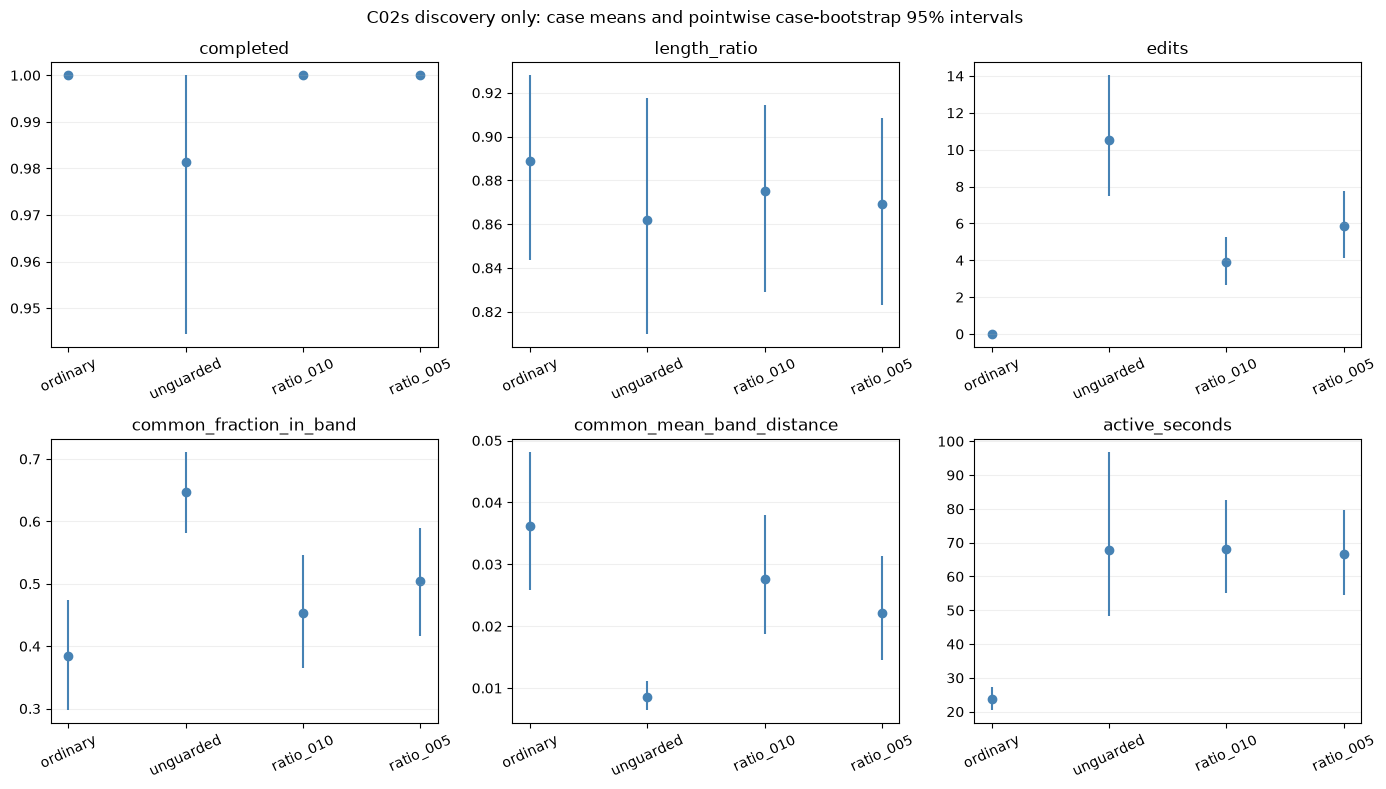

In [10]:
states={}; records=[]; review=[]; edit_rows=[]
for c in cases:
    for arm in ARMS:
        folder=OUT/c['case_id']/arm
        payload=json.loads((folder/'state.json').read_text())
        assert payload['run_hash']==RUN_HASH
        s=payload['state'];states[c['case_id'],arm]=s
    horizon=min(len(states[c['case_id'],a]['words']) for a in ARMS)
    for arm in ARMS:
        s=states[c['case_id'],arm]; W=len(s['words'])
        metrics=trajectory_metrics(s['trajectory'],c['warmup_words'])
        common=trajectory_metrics([t for t in s['trajectory'] if t['W_after']<=horizon],c['warmup_words'])
        reasons=Counter(t.get('fallback_reason') for t in s['trajectory'] if t.get('fallback_reason'))
        records.append(dict(case_id=c['case_id'],domain=c['domain'],arm=arm,
            completed=int(s['status']=='completed_eos'),status=s['status'],
            words=W,length_ratio=W/c['W_ref'],unique_share=len(set(s['words']))/W if W else np.nan,
            edits=s['replacements'],fallbacks=s['fallbacks'],
            ratio_rejections=reasons['relative_likelihood_rejected'],
            search_budget_exits=reasons['search_budget'],
            candidate_limit_exits=reasons['candidate_limit'],
            exhausted_fallbacks=reasons['exhausted'],
            active_seconds=json.loads((OUT/c['case_id']/arm/'state.json').read_text())['active_seconds'],
            common_horizon=horizon,
            common_fraction_in_band=common['fraction_in_band'],
            common_mean_band_distance=common['mean_band_distance'],
            **metrics))
        review.append(dict(case_id=c['case_id'],arm=arm,status=s['status'],
            source=c['original'],text=s['committed_text']))
        for t in s['trajectory']:
            if t['action']=='backtracked':
                edit_rows.append(dict(case_id=c['case_id'],arm=arm,
                    word_index=t['word_index'],ordinary_word=t['original_word'],
                    chosen_word=t['word'],mode=t['mode_before']))
metrics=pd.DataFrame(records)
metrics.to_csv(OUT/'generation_metrics.csv',index=False)
pd.DataFrame(review).to_csv(OUT/'generation_texts.csv',index=False)
pd.DataFrame(edit_rows).to_csv(OUT/'accepted_word_decisions.csv',index=False)
review_path=OUT/'manual_review.csv'
if not review_path.exists():
    pd.DataFrame(review).assign(
        grammar_acceptable='',task_utility='',essential_information_preserved='',
        admissible_variation='',repetition='',notes=''
    ).to_csv(review_path,index=False)
display(metrics.groupby('arm').agg(
    attempted=('case_id','size'),completed=('completed','sum'),
    mean_words=('words','mean'),mean_edits=('edits','mean'),
    mean_ratio_rejections=('ratio_rejections','mean'),
    mean_common_band_attainment=('common_fraction_in_band','mean'),
    mean_common_distance=('common_mean_band_distance','mean')))

# Paired bootstrap: finite pairs only; expose their denominator.
metric_names=['completed','length_ratio','edits','common_fraction_in_band',
              'common_mean_band_distance','active_seconds']
comparisons=[('ratio_010','unguarded'),('ratio_005','unguarded'),('ratio_005','ratio_010')]
rows=[]
for metric in metric_names:
    wide=metrics.pivot(index='case_id',columns='arm',values=metric)
    for arm,base in comparisons:
        delta=(wide[arm]-wide[base]).dropna().to_numpy(float)
        if not len(delta): continue
        rng=np.random.default_rng(SELECTION_SEED)
        b=delta[rng.integers(len(delta),size=(BOOTSTRAPS,len(delta)))].mean(1)
        rows.append(dict(metric=metric,comparison=f'{arm} minus {base}',
            n_pairs=len(delta),mean_change=delta.mean(),
            ci_low=np.quantile(b,.025),ci_high=np.quantile(b,.975)))
paired=pd.DataFrame(rows)
paired.to_csv(OUT/'paired_generation_changes.csv',index=False)
display(paired)

fig,axes=plt.subplots(2,3,figsize=(14,8))
labels=list(ARMS)
for ax,metric in zip(axes.flat,metric_names):
    for i,arm in enumerate(labels):
        v=metrics.loc[metrics.arm==arm,metric].dropna().to_numpy(float)
        if not len(v): continue
        rng=np.random.default_rng(SELECTION_SEED)
        means=v[rng.integers(len(v),size=(BOOTSTRAPS,len(v)))].mean(1)
        lo,hi=np.quantile(means,[.025,.975])
        ax.vlines(i,lo,hi,color='steelblue');ax.scatter(i,v.mean(),color='steelblue')
    ax.set_xticks(range(4),labels,rotation=25);ax.set_title(metric);ax.grid(axis='y',alpha=.2)
fig.suptitle('C02s discovery only: case means and pointwise case-bootstrap 95% intervals')
fig.tight_layout();savefig(fig,'generation_guard_sensitivity');plt.show()


## 5. Downstream comparison under the frozen gate
Reuses the human-reference IDs and bounds saved in C02r's treatment contract. Only cases completed in every arm and satisfying the length-support rule against that same pool in every arm enter this paired comparison. No rematching or gate rediscovery. This secondary subset cannot replace the all-attempt completion report. Stage changes compare Unique → sentence means → final punctuation; ordinary is also passed through these same downstream stages as an ablation.

In [11]:
# Free Qwen before GPT-2. Generation cells above can be resumed after
# rerunning the model-definition cell, not with the GPT-2 model below.
if 'backend' in globals(): del backend
del model, tokenizer
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()
features=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert corpus.source_id.is_unique
text_map=corpus.set_index('source_id').text.to_dict()
feature_map=features.set_index('source_id')
humans=features.loc[(features.dataset=='raid')&(features.split=='train')&(features.label==0)].copy()
parent_treatment=json.loads((PARENT/'treatment_contract.json').read_text())
frozen_refs={r['case_id']:r for r in parent_treatment['prepared'] if r['case_id'] in selected_ids}
gate=json.loads((PARENT/'frozen_punctuation_gate.json').read_text())
GATE_HASH=digest(gate)
active=gate['active_denominators']
PMARKS={'semicolon':';','colon':':','hyphen':'-','en_dash':'–','em_dash':'—','comma':','}
DENOMS=['relative','per_sentence']
assert set(gate['discovery_ids']).issubset(selected_ids)
SCORER_ID=parent_treatment['scorer']
SCORER_REVISION=parent_treatment['scorer_revision']
assert SCORER_REVISION and SCORER_REVISION!='main'
LEFT_WORDS=48;RIGHT_WORDS=32


In [12]:
from functools import lru_cache
def measure(doc):
    sentences = [s for s in doc.sents if any(t.is_alpha for t in s)]
    tokens = [t for t in doc if t.is_alpha]
    seqs = {
        'wps': [sum(t.is_alpha for t in s) for s in sentences],
        'cps': [len(s.text.strip()) for s in sentences],
        'cpw': [len(t.text) for t in tokens],
    }
    W, S, C = len(tokens), len(sentences), len(doc.text)
    result = {'W':W, 'S':S, 'C':C,
              'detector_C_over_W': C/W if W else np.nan,
              'detector_C_over_S': C/S if S else np.nan,
              'share_unique_words': len({t.text.lower() for t in tokens})/W if W else np.nan}
    for name, seq in seqs.items():
        a = np.asarray(seq, dtype=float)
        result[name+'_mean'] = float(a.mean()) if len(a) else np.nan
        result[name+'_var'] = float(a.var(ddof=0)) if len(a) else np.nan
    return result, seqs



@lru_cache(maxsize=8192)
def stats_for(text): return measure(nlp(text))[0]


human_stats={sid:stats_for(normalize(text_map[sid])) for sid in humans.source_id}
prepared_by_arm={arm:[] for arm in ARMS}
exclusions=[]
for c in cases:
    cid=c['case_id']
    if any(states[cid,a]['status']!='completed_eos' for a in ARMS):
        exclusions.append(dict(case_id=cid,reason='not_completed_in_all_arms'));continue
    if cid not in frozen_refs:
        exclusions.append(dict(case_id=cid,reason='no_parent_fixed_reference_pool'));continue
    refs=frozen_refs[cid]['reference_ids']
    texts={a:normalize(states[cid,a]['committed_text']) for a in ARMS}
    support={a:sum(
        human_stats[r]['S']>0 and
        stats_for(t)['W']/LENGTH_RATIO<=human_stats[r]['W']<=stats_for(t)['W']*LENGTH_RATIO
        for r in refs) for a,t in texts.items()}
    # Keep the complete fixed pool eligible in every arm, without rematching.
    if len(refs)<15 or any(n!=len(refs) for n in support.values()):
        exclusions.append(dict(case_id=cid,reason='fixed_pool_outside_length_window',
                               support_by_arm=json.dumps(support)));continue
    for a,t in texts.items():
        prepared_by_arm[a].append({**c,'text':t,'reference_ids':refs,
                                  'bounds':frozen_refs[cid]['bounds']})
pd.DataFrame(exclusions).to_csv(OUT/'downstream_exclusions.csv',index=False)
common_ids=[c['case_id'] for c in prepared_by_arm['ordinary']]
print('Common downstream cases:',len(common_ids),'of',len(cases))
assert common_ids, 'No common supported cohort: inspect downstream_exclusions.csv.'
display(pd.DataFrame(exclusions))


Common downstream cases: 27 of 54


,case_id,reason,support_by_arm
0,gate_0004,not_completed_in_all_arms,NaN
1,gate_0005,no_parent_fixed_reference_pool,NaN
2,gate_0007,fixed_pool_outside_length_window,"{""ordinary"": 7, ""unguarded"": 30, ""ratio_010"": ..."
3,gate_0015,fixed_pool_outside_length_window,"{""ordinary"": 30, ""unguarded"": 30, ""ratio_010"":..."
4,gate_0016,fixed_pool_outside_length_window,"{""ordinary"": 20, ""unguarded"": 30, ""ratio_010"":..."
5,gate_0019,fixed_pool_outside_length_window,"{""ordinary"": 30, ""unguarded"": 30, ""ratio_010"":..."
6,gate_0020,no_parent_fixed_reference_pool,NaN
7,gate_0023,fixed_pool_outside_length_window,"{""ordinary"": 15, ""unguarded"": 30, ""ratio_010"":..."
8,gate_0024,fixed_pool_outside_length_window,"{""ordinary"": 25, ""unguarded"": 30, ""ratio_010"":..."
9,gate_0026,fixed_pool_outside_length_window,"{""ordinary"": 28, ""unguarded"": 30, ""ratio_010"":..."


In [13]:
tokenizer=AutoTokenizer.from_pretrained(SCORER_ID,revision=SCORER_REVISION,use_fast=True)
model=AutoModelForCausalLM.from_pretrained(SCORER_ID,revision=SCORER_REVISION)
device='cuda' if torch.cuda.is_available() else 'cpu';model.to(device).eval()
# Score at most the model context; reject overflow rather than silently truncating.
@torch.inference_mode()
def continuation_score(left,tail):
    enc=tokenizer(left+tail,return_offsets_mapping=True,return_tensors='pt',add_special_tokens=False)
    offsets=enc.pop('offset_mapping')[0].tolist();ids=enc['input_ids'].to(device)
    if ids.shape[1]<2 or ids.shape[1]>model.config.max_position_embeddings:return None
    logp=model(input_ids=ids).logits[0,:-1].log_softmax(-1)
    chosen=logp.gather(1,ids[0,1:,None]).squeeze(1)
    mask=torch.tensor([end>len(left) for start,end in offsets[1:]],device=device)
    return float(chosen[mask].mean()) if mask.any() else None

def score_edit(text,e):
    a,b,replacement=e['start'],e['end'],e['replacement']
    left_parts=list(re.finditer(r'\S+',text[:a]));right_parts=list(re.finditer(r'\S+',text[b:]))
    left=text[left_parts[-LEFT_WORDS].start() if len(left_parts)>=LEFT_WORDS else 0:a]
    right=text[b:b+(right_parts[RIGHT_WORDS-1].end() if len(right_parts)>=RIGHT_WORDS else len(text)-b)]
    # Fixed flanks shared by both alternatives; future text contributes to each score.
    before=continuation_score(left,text[a:b]+right);after=continuation_score(left,replacement+right)
    if before is None or after is None:return None
    return dict(mutability=math.exp(min(0.,after-before)),score_before=before,score_after=after)



Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 11671.22it/s]


In [14]:
SENT_METRICS=['wps_mean','cps_mean']
def bar(q): return .05+.90/(1+math.exp(float(np.clip(4*(q-1),-60,60))))
def independent(text):
    d=nlp(text.strip())
    return any(t.dep_=='ROOT' and t.pos_ in {'VERB','AUX'} and
               any(c.dep_ in {'nsubj','nsubjpass','csubj','expl'} for c in t.children) for t in d)

def signature(text):
    return [(t.text.lower(),len(t.text)) for t in nlp.make_doc(text) if t.is_alpha]

def apply_ops(text,ops):
    for a,b,r in sorted(ops,reverse=True):text=text[:a]+r+text[b:]
    return text

def proposals(text):
    doc=nlp(text); sentences=[s for s in doc.sents if any(t.is_alpha for t in s)]
    splits=[]; merges=[]
    for s in sentences:
        for t in s:
            if t.text not in {';',','}:continue
            # Every comma joining two independent clauses is considered.
            left=text[s.start_char:t.idx];right=text[t.idx+1:s.end_char]
            if independent(left) and independent(right):
                # Capitalize the first alphabetic character after the new boundary.
                match=re.search(r'[A-Za-z]',right)
                if match:
                    j=t.idx+1+match.start()
                    splits.append([(t.idx,t.idx+1,'.'),(j,j+1,text[j].upper())])
    for a,b in zip(sentences,sentences[1:]):
        # Restrict merging to plain periods between two independent clauses.
        end=a.end_char
        if text[end-1:end]!='.' or text[end:b.start_char].strip():continue
        if independent(a.text[:-1]) and independent(b.text):
            merges.append([(end-1,end,';')])
    out=[('split',o) for o in splits]+[('merge',o) for o in merges]
    for a in splits:
        for b in merges:
            if all(x[1]<=y[0] or y[1]<=x[0] for x in a for y in b):
                out.append(('boundary_shift',a+b))
    seen=set()
    for rule,ops in out:
        candidate=apply_ops(text,ops)
        if candidate not in seen:
            seen.add(candidate);yield rule,ops,candidate

def distances(stats,b):
    return np.array([max(b[m]['low']-stats[m],0,stats[m]-b[m]['high']) /
        max(b[m]['high']-b[m]['low'],1.0) for m in SENT_METRICS])

def run_case(c):
    text=c['text']; audit=[]; initial_sig=signature(text)
    stats,_=measure(nlp(text));initial=stats.copy(); seen={text}
    while True:
        before_d=distances(stats,c['bounds']); loss=float(before_d.sum())
        if loss<=1e-12: status='in_band';break
        threshold=bar(float(before_d.max()))
        accepted=[]; checked=0
        for rule,ops,candidate in proposals(text):
            checked+=1
            if candidate in seen or signature(candidate)!=initial_sig:continue
            after,_=measure(nlp(candidate))
            expected_delta={'split':1,'merge':-1,'boundary_shift':0}[rule]
            if after['S']!=stats['S']+expected_delta or after['S']<2:continue
            d=distances(after,c['bounds'])
            if d.sum()>=loss-1e-10:continue
            a=min(o[0] for o in ops); b=max(o[1] for o in ops)
            replacement=apply_ops(text[a:b],[(x-a,y-a,r) for x,y,r in ops])
            score=score_edit(text,dict(start=a,end=b,replacement=replacement))
            if score is None or score['mutability']<threshold:continue
            accepted.append((score['mutability'],loss-float(d.sum()),rule,ops,candidate,after,score))
        if not accepted:status='no_eligible_improving_candidate';break
        accepted.sort(key=lambda x:(-x[0],-x[1],x[2],x[4]))
        mut,gain,rule,ops,candidate,after,score=accepted[0]
        audit.append(dict(step=len(audit)+1,rule=rule,ops=ops,before=stats,after=after,
            objective_before=loss,objective_after=loss-gain,threshold=threshold,**score))
        text=candidate;stats=after;seen.add(text)
        print(c['case_id'],len(audit),rule,'loss=',round(loss-gain,4),flush=True)
    assert signature(text)==initial_sig
    for m in ['cpw_mean','cpw_var','share_unique_words']:
        assert np.isclose(stats[m],initial[m],atol=1e-12)
    return dict(text=text,status=status,audit=audit,initial=initial,final=stats,contract_hash=CONTRACT_HASH)




In [15]:
DOWNSTREAM_CONTRACT=dict(run_hash=RUN_HASH,gate=gate,
    input_hashes={str(p):file_hash(p) for p in [BASE/'google-10000-english.txt',
        PRIOR/'fz118_raid_no_parentheses_detector.pkl',PRIOR/'fz118_raid_model_features.json',
        BASE/'fz118_paired_features.parquet',BASE/'paired_corpus.parquet']},
    parent_treatment_hash=digest(parent_treatment),common_ids=common_ids,
    reference_policy='complete_parent_pool_eligible_in_every_arm',
    scorer_revision=SCORER_REVISION,
    sentence_implementation=hashlib.sha256(inspect.getsource(run_case).encode()).hexdigest())
freeze(OUT/'downstream_contract.json',DOWNSTREAM_CONTRACT)
CONTRACT_HASH=digest(DOWNSTREAM_CONTRACT)
sentence_results={}
for arm in ARMS:
    results=[]
    for c in prepared_by_arm[arm]:
        path=OUT/c['case_id']/arm/'sentence.json'
        if path.exists():
            result=json.loads(path.read_text())
            assert result['contract_hash']==CONTRACT_HASH
        else:
            result=run_case(c);write_json(path,result)
        results.append((c,result))
    sentence_results[arm]=results


gate_0003 1 split loss= 1.4344
gate_0003 2 split loss= 0.4175
gate_0017 1 split loss= 0.0
gate_0018 1 split loss= 0.1403
gate_0022 1 merge loss= 0.985
gate_0022 2 merge loss= 0.0
gate_0051 1 merge loss= 0.1145
gate_0054 1 split loss= 0.0484
gate_0070 1 split loss= 0.1344
gate_0076 1 split loss= 1.5544
gate_0076 2 split loss= 0.0205
gate_0088 1 merge loss= 0.3476
gate_0090 1 merge loss= 0.0
gate_0094 1 split loss= 0.0224
gate_0095 1 split loss= 0.5251
gate_0003 1 split loss= 0.7874
gate_0017 1 split loss= 0.0
gate_0018 1 split loss= 0.1244
gate_0022 1 merge loss= 0.6589
gate_0022 2 merge loss= 0.0
gate_0035 1 merge loss= 0.0
gate_0051 1 merge loss= 0.1145
gate_0070 1 split loss= 0.0
gate_0076 1 split loss= 1.1742
gate_0076 2 split loss= 0.0
gate_0088 1 merge loss= 0.3772
gate_0090 1 merge loss= 0.0
gate_0095 1 split loss= 0.5251
gate_0003 1 split loss= 1.3103
gate_0003 2 split loss= 0.3693
gate_0017 1 split loss= 0.0
gate_0018 1 split loss= 0.1403
gate_0022 1 merge loss= 0.6589
gate_002

In [16]:
import re, pickle
from collections import Counter
import textstat
PUNCTUATION = [('comma', ','), ('period', '.'), ('colon', ':'), ('semicolon', ';'),
    ('question', '?'), ('exclamation', '!'), ('hyphen', '-'), ('quote', '"'),
    ('lparen', '('), ('rparen', ')'), ('lbracket', '['), ('rbracket', ']'), ('newline', '\n')]
google_words=[w.strip().lower() for w in (BASE/'google-10000-english.txt').read_text().splitlines() if w.strip()]
GOOGLE_TOP={n:set(google_words[:n]) for n in [100,1000,10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector
# Exact tree-path contributions, summed across the frozen forest.
FEATURE_NAMES=json.loads((BASE/'fz118_feature_contract.json').read_text())['feature_names']
model_features=json.loads((PRIOR/'fz118_raid_model_features.json').read_text())
with (PRIOR/'fz118_raid_no_parentheses_detector.pkl').open('rb') as f:detector=pickle.load(f)
assert list(detector.classes_)==[0,1]
def contributions(X):
    a=np.asarray(X,dtype=np.float32); output=np.zeros_like(a,dtype=float);bias=0.
    for estimator in detector.estimators_:
        tree=estimator.tree_; value=tree.value[:,0,:].astype(float)
        prob=value[:,1]/value.sum(axis=1);bias+=prob[0]/len(detector.estimators_)
        for i,row in enumerate(a):
            node=0
            while tree.children_left[node]!=tree.children_right[node]:
                feature=tree.feature[node]
                child=tree.children_left[node] if row[feature]<=tree.threshold[node] else tree.children_right[node]
                output[i,feature]+=(prob[child]-prob[node])/len(detector.estimators_)
                node=child
    assert np.allclose(bias+output.sum(axis=1),detector.predict_proba(X)[:,1],atol=1e-8)
    return output


@lru_cache(maxsize=8192)
def vector_for(text): return extract_fz118(normalize(text))
def frame_for(texts):
    return pd.DataFrame([vector_for(t) for t in texts],columns=FEATURE_NAMES)
for c in cases:
    np.testing.assert_allclose(
        extract_fz118(normalize(c['original'])),
        feature_map.loc[c['source_id'],FEATURE_NAMES].to_numpy(float),atol=1e-9,rtol=0)


## 6. Punctuation targets and enforcement
Uses the original gate and C02r target policy. Case-keyed random draws are shared across arms; integer targets may differ because exposure differs. This tests pipeline behavior, not identical numeric targets. Protected punctuation counts are checked within each arm. No detector score selects edits.

In [17]:
evaluation=sentence_results['ordinary']
def stable_rng(*parts):
    return np.random.default_rng(int(hashlib.sha256(json.dumps([SELECTION_SEED,*parts]).encode()).hexdigest()[:16],16))
def rates(text):
    st=stats_for(text)
    return {(m,d):text.count(sym)/(st['C'] if d=='relative' else st['S']) for m,sym in PMARKS.items() for d in DENOMS}
def outside(x,lo,hi): return max(lo-x,0.,x-hi)
training=features.loc[(features.dataset=='raid')&(features.split=='train')].copy()
genre_ref={}
needed=[(m,d) for m,ds in active.items() for d in ds]
for genre in sorted({c['domain'] for c,s in evaluation}):
    g=training.loc[training.domain==genre]
    hr=[rates(normalize(text_map[r])) for r in g.loc[g.label==0,'source_id']]
    ar=[rates(normalize(text_map[r])) for r in g.loc[g.label==1,'source_id']]
    assert len(hr)>=15 and len(ar)>=15
    for m,d in needed:
        h=np.array([r[m,d] for r in hr]); a=np.array([r[m,d] for r in ar])
        rg=stable_rng('genre',genre,m,d)
        sd=float(np.std([h[rg.integers(len(h),size=len(h))].mean() for _ in range(BOOTSTRAPS)],ddof=1))
        mu=float(h.mean()); direction=float(np.sign(a.mean()-mu))
        genre_ref[genre,m,d]=dict(mean=mu,sd=sd,lo=max(0,mu-ARTIFICIAL_SD_SCALE*sd),hi=mu+ARTIFICIAL_SD_SCALE*sd,direction=direction)

compound_examples={}
for genre in sorted({c['domain'] for c,s in evaluation}):
    forms=set()
    for sid in humans.loc[humans.domain==genre,'source_id']:
        forms.update(x.lower() for x in re.findall(r'\b[A-Za-z]+(?:-[A-Za-z]+)+\b',str(text_map[sid])))
    compound_examples[genre]=forms

def vertices(text,mark,genre):
    doc=nlp(text); out=set(); symbol=PMARKS[mark]
    def emit(a,b,r):
        old=text[a:b]
        if old==r or any(x in old+r for x in '.?!'):return
        if any(sym in old+r for m,sym in PMARKS.items() if m not in (mark,'comma')):return
        out.add((a,b,r))
    for hit in re.finditer(re.escape(symbol),text):
        a,b=hit.span()
        if (a and text[a-1].isdigit()) or (b<len(text) and text[b].isdigit()):continue
        if mark=='comma': emit(a,b,' ' if a and b<len(text) and text[a-1].isalnum() and text[b].isalnum() else '')
        elif mark=='hyphen' and a and b<len(text) and text[a-1].isalpha() and text[b].isalpha():emit(a,b,' ')
        else:
            while a and text[a-1] in ' \t':a-=1
            while b<len(text) and text[b] in ' \t':b+=1
            options={';':[', and ', ', but ', ', so ', ', '], ':':[', namely ', ', including ', ' including ', ', specifically ', ', which is ', ', which are ', ' such as ', ', ']}.get(symbol,[', ',' ', ', namely ', ', and ', ', which is ', ', which are '])
            for r in options:emit(a,b,r)
    for sent in doc.sents:
        if mark=='semicolon':
            for hit in re.finditer(r',\s*|\b(?:and|but|yet|so)\b',sent.text,re.I):
                a,b=sent.start_char+hit.start(),sent.start_char+hit.end()
                if independent(text[sent.start_char:a]) and independent(text[b:sent.end_char]):emit(a,b,'; ')
        if mark in ['colon','hyphen','en_dash','em_dash']:
            for hit in re.finditer(r'\b(?:namely|specifically|including|such as|that is|in other words)\b',sent.text,re.I):
                a,b=sent.start_char+hit.start(),sent.start_char+hit.end()
                if any(t.isalpha() for t in text[sent.start_char:a]) and any(t.isalpha() for t in text[b:sent.end_char]):emit(a,b,' '+symbol+' ')
        if mark=='comma':
            for t in sent:
                if t.dep_ not in {'advcl','appos','relcl','parataxis','conj','prep'}:continue
                subtree=list(t.subtree);a=min(x.idx for x in subtree);b=max(x.idx+len(x.text) for x in subtree)
                if a<sent.start_char or b>sent.end_char:continue
                if a>sent.start_char and text[a-1].isspace() and text[:a].rstrip()[-1:] not in ',;:—–-.?!':emit(a,a,', ')
                if b<sent.end_char and text[b:b+1].isspace() and t.dep_ in {'advcl','appos','relcl','prep'}:emit(b,b,',')
    if mark=='hyphen':
        toks=list(doc)
        for left,right in zip(toks,toks[1:]):
            a=left.idx+len(left.text);b=right.idx
            if left.is_alpha and right.is_alpha and text[a:b].isspace() and (left.text+'-'+right.text).lower() in compound_examples[genre]:emit(a,b,'-')
    for a,b,r in sorted(out):yield dict(start=a,end=b,replacement=r)

def mark_loss(text,p,mark):
    target=p['targets'][mark]
    if target is not None:return abs(text.count(PMARKS[mark])-target)
    st=stats_for(text); vals=rates(text); total=0.
    for d in active[mark]:
        lo,hi=p['local'][mark,d]
        exposure=p['initial']['C'] if d=='relative' else p['initial']['S']
        total+=outside(vals[mark,d],lo,hi)/max(hi-lo,1/exposure)
    return total

def enforce(p):
    text=p['text']; initial=p['initial'];c=p['case'];seen={text};edits=[];stops=[];done=[]
    for mark,ds in active.items():
        if not ds:continue
        while True:
            loss=mark_loss(text,p,mark)
            if loss<=1e-10:
                stops.append(dict(mark=mark,status='in_assigned_target',loss=loss));done.append(mark);break
            counters=Counter(); eligible=[]
            for e in vertices(text,mark,c['domain']):
                counters['proposed']+=1
                candidate=text[:e['start']]+e['replacement']+text[e['end']:]
                if candidate in seen:counters['visited']+=1;continue
                after=stats_for(candidate)
                if after['S']!=initial['S'] or any(candidate.count(x)!=p['text'].count(x) for x in '.?!'):
                    counters['boundary_change']+=1;continue
                if any(candidate.count(sym)!=text.count(sym) for m,sym in PMARKS.items() if m not in [mark,'comma']):
                    counters['other_nontrivial_change']+=1;continue
                if any(outside(after[m],c['bounds'][m]['low'],c['bounds'][m]['high'])>
                       outside(initial[m],c['bounds'][m]['low'],c['bounds'][m]['high'])+MEAN_DISTANCE_TOLERANCE[m]+1e-10 for m in SENT_METRICS):
                    counters['mean_control_regression']+=1;continue
                if any(mark_loss(candidate,p,m)>1e-10 for m in done):counters['completed_target_regression']+=1;continue
                newloss=mark_loss(candidate,p,mark)
                if newloss>=loss-1e-10:counters['no_target_improvement']+=1;continue
                score=score_edit(text,e)
                if score is None:counters['unscorable']+=1;continue
                eligible.append((score['mutability'],loss-newloss,candidate,e,score))
            stops.append(dict(mark=mark,status='search_iteration',loss=loss,**counters,eligible=len(eligible)))
            if not eligible:
                stops.append(dict(mark=mark,status='enumerated_candidates_exhausted',loss=loss));break
            eligible.sort(key=lambda r:(-r[0],-r[1],r[2]))
            mut,gain,candidate,e,score=eligible[0]
            edits.append(dict(mark=mark,before=text,after=candidate,loss_before=loss,loss_after=loss-gain,edit=e,**score))
            text=candidate;seen.add(text)
        print(c['case_id'],mark,'loss',round(mark_loss(text,p,mark),5),flush=True)
    assert all(text.count(x)==p['text'].count(x) for x in '.?!')
    assert stats_for(text)['S']==initial['S']
    assert all(text.count(PMARKS[m])==p['text'].count(PMARKS[m]) for m,ds in active.items() if not ds)
    return dict(text=text,edits=edits,stops=stops)



In [18]:
final_by_arm={}
for arm in ARMS:
    evaluation=sentence_results[arm]
    punct_cases=[]; target_rows=[]
    for c,s in evaluation:
        text=s['text']; st=stats_for(text); local={}; targets={}
        ref_rates=[rates(normalize(text_map[r])) for r in c['reference_ids']]
        for m,ds in active.items():
            if not ds: continue
            tests=[]
            for d in ds:
                lo,hi=map(float,np.quantile([r[m,d] for r in ref_rates],[.2,.6]))
                local[m,d]=(lo,hi); g=genre_ref[c['domain'],m,d]
                trigger=(g['direction']>0 and lo>g['hi']) or (g['direction']<0 and hi<g['lo'])
                distance=max(g['lo']-hi,lo-g['hi'],0)/max(g['sd'],abs(g['mean'])*1e-6,1e-12)
                probability=BUMP_P_MIN+(1-BUMP_P_MIN)/(1+distance) if trigger else 0.
                tests.append(dict(denominator=d,local_low=lo,local_high=hi,human_mean=g['mean'],bootstrap_sd=g['sd'],trigger=trigger,probability=probability))
            probability=max(t['probability'] for t in tests)
            rg=stable_rng('target',c['case_id'],m);draw=float(rg.random());bumped=draw<probability
            basis='per_sentence' if 'per_sentence' in ds else 'relative'
            expected=genre_ref[c['domain'],m,basis]['mean']*(st['S'] if basis=='per_sentence' else st['C'])
            target=int(np.floor(expected)+(rg.random()<expected%1)) if bumped else None
            targets[m]=target
            for t in tests:target_rows.append(dict(case_id=c['case_id'],mark=m,**t,mark_probability=probability,draw=draw,bumped=bumped,expected_count=expected,target_count=target))
        punct_cases.append(dict(case=c,text=text,initial=st,local=local,targets=targets))
    arm_dir=OUT/'summaries'/arm;arm_dir.mkdir(parents=True,exist_ok=True)
    pd.DataFrame(target_rows).to_csv(arm_dir/'assigned_targets.csv',index=False)
    # Include complete implementations and inputs in the per-arm contract.
    punct_hash=digest(dict(downstream_hash=CONTRACT_HASH,arm=arm,
        targets=target_rows,gate_hash=GATE_HASH,
        code=inspect.getsource(enforce)+inspect.getsource(vertices)+inspect.getsource(mark_loss)))
    final_results=[]
    for p in punct_cases:
        path=OUT/p['case']['case_id']/arm/'punctuation.json'
        if path.exists():
            result=json.loads(path.read_text())
            assert result['contract_hash']==punct_hash
        else:
            result={**enforce(p),'contract_hash':punct_hash}
            write_json(path,result)
        final_results.append((p,result))
    final_by_arm[arm]=final_results


gate_0001 colon loss 0.0
gate_0001 hyphen loss 0
gate_0001 comma loss 0
gate_0003 colon loss 0.0
gate_0003 hyphen loss 0.0
gate_0003 comma loss 0.0
gate_0017 colon loss 0.0
gate_0017 hyphen loss 0.0
gate_0017 comma loss 0.0
gate_0018 colon loss 0.125
gate_0018 hyphen loss 0.0
gate_0018 comma loss 0.0
gate_0021 colon loss 0.0
gate_0021 hyphen loss 0.0
gate_0021 comma loss 0.0
gate_0022 colon loss 0.0
gate_0022 hyphen loss 3
gate_0022 comma loss 0.0
gate_0025 colon loss 0.0
gate_0025 hyphen loss 0.0
gate_0025 comma loss 0.29268
gate_0027 colon loss 0.0
gate_0027 hyphen loss 1
gate_0027 comma loss 0.0
gate_0035 colon loss 0.0
gate_0035 hyphen loss 0.0
gate_0035 comma loss 0.0
gate_0037 colon loss 0.0
gate_0037 hyphen loss 0.0
gate_0037 comma loss 0.0
gate_0051 colon loss 0.0
gate_0051 hyphen loss 0.0
gate_0051 comma loss 0.0
gate_0054 colon loss 0.0
gate_0054 hyphen loss 0.12032
gate_0054 comma loss 0.0
gate_0067 colon loss 0.0
gate_0067 hyphen loss 0.0
gate_0067 comma loss 0.0
gate_0070 

## 7. Paired downstream outcomes and text review
Report the same cases in every arm and stage. The raw band-control results above remain primary for guard sensitivity. Detector scores here are secondary discovery diagnostics; do not select the ratio solely for a smaller score or present these as held-out ROC results.

,stage,comparison,n_pairs,mean_change,ci_low,ci_high
0,unique,ratio_010 minus unguarded,27,0.005835,-0.006035,0.019749
1,unique,ratio_005 minus unguarded,27,-0.003733,-0.011047,0.003852
2,unique,ratio_005 minus ratio_010,27,-0.009569,-0.020423,-0.001761
3,sentence,ratio_010 minus unguarded,27,0.010109,-0.006292,0.031505
4,sentence,ratio_005 minus unguarded,27,-0.001328,-0.008559,0.006944
5,sentence,ratio_005 minus ratio_010,27,-0.011437,-0.025511,-0.001041
6,final,ratio_010 minus unguarded,27,0.014397,-0.003769,0.037233
7,final,ratio_005 minus unguarded,27,0.002673,-0.006688,0.012309
8,final,ratio_005 minus ratio_010,27,-0.011724,-0.026071,-0.000642


met  cases
arm       mark              
ordinary  colon    25     27
          comma    26     27
          hyphen   19     27
ratio_005 colon    25     27
          comma    26     27
          hyphen   19     27
ratio_010 colon    25     27
          comma    26     27
          hyphen   19     27
unguarded colon    25     27
          comma    26     27
          hyphen   18     27

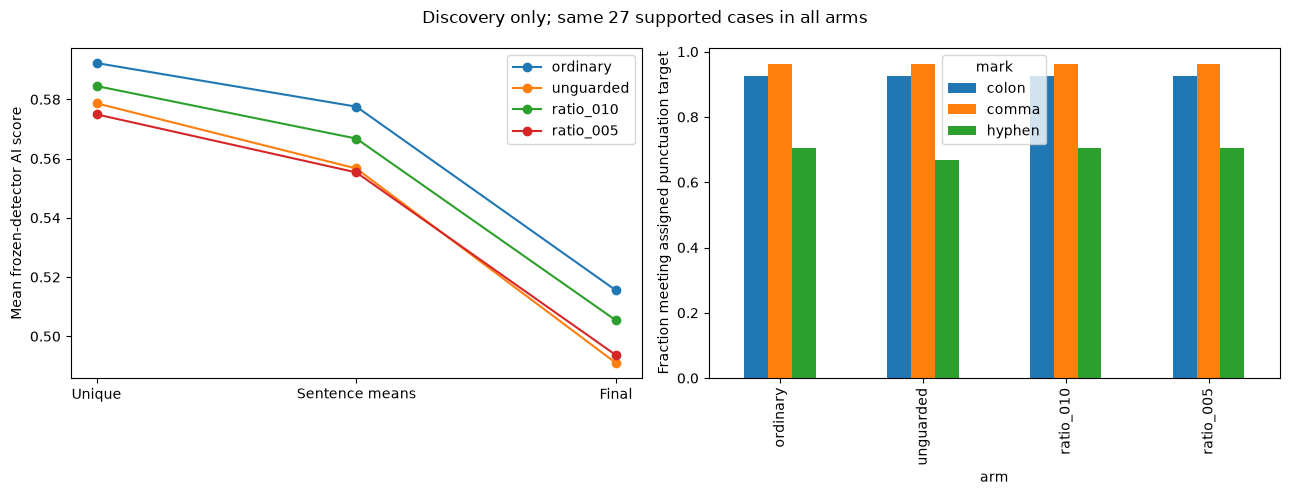

In [19]:
score_rows=[];target_outcomes=[];texts=[];feature_rows=[]
for arm in ARMS:
    for p,r in final_by_arm[arm]:
        c=p['case'];cid=c['case_id']
        stages={'unique':normalize(states[cid,arm]['committed_text']),
                'sentence':p['text'],'final':r['text']}
        X=frame_for(list(stages.values()))
        scores=detector.predict_proba(X[model_features])[:,1]
        for j,(stage,text) in enumerate(stages.items()):
            score_rows.append(dict(case_id=cid,arm=arm,stage=stage,
                                   AI_score=float(scores[j]),**stats_for(text)))
            feature_rows.append(dict(case_id=cid,arm=arm,stage=stage,
                                     **dict(zip(FEATURE_NAMES,X.iloc[j]))))
            texts.append(dict(case_id=cid,arm=arm,stage=stage,text=text))
        for m,ds in active.items():
            if ds:
                target_outcomes.append(dict(case_id=cid,arm=arm,mark=m,
                    loss=mark_loss(r['text'],p,m),
                    met=mark_loss(r['text'],p,m)<=1e-10))
score_frame=pd.DataFrame(score_rows);scores_path=OUT/'downstream_scores.csv'
score_frame.to_csv(scores_path,index=False)
pd.DataFrame(feature_rows).to_csv(OUT/'downstream_features.csv',index=False)
pd.DataFrame(texts).to_csv(OUT/'downstream_texts.csv',index=False)
targets=pd.DataFrame(target_outcomes);targets.to_csv(OUT/'downstream_targets.csv',index=False)
review_path=OUT/'downstream_manual_review.csv'
if not review_path.exists():
    pd.DataFrame(texts).assign(grammar_acceptable='',task_utility='',
        essential_information_preserved='',notes='').to_csv(review_path,index=False)

rows=[]
for stage in ['unique','sentence','final']:
    wide=score_frame.loc[score_frame.stage==stage].pivot(index='case_id',columns='arm',values='AI_score')
    for arm,base in comparisons:
        d=(wide[arm]-wide[base]).to_numpy()
        rng=np.random.default_rng(SELECTION_SEED)
        b=d[rng.integers(len(d),size=(BOOTSTRAPS,len(d)))].mean(1)
        rows.append(dict(stage=stage,comparison=f'{arm} minus {base}',
            n_pairs=len(d),mean_change=d.mean(),ci_low=np.quantile(b,.025),
            ci_high=np.quantile(b,.975)))
pd.DataFrame(rows).to_csv(OUT/'paired_downstream_score_changes.csv',index=False)
display(pd.DataFrame(rows))
display(targets.groupby(['arm','mark']).agg(met=('met','sum'),cases=('case_id','size')))
fig,axes=plt.subplots(1,2,figsize=(13,5))
for arm in ARMS:
    means=score_frame.loc[score_frame.arm==arm].groupby('stage').AI_score.mean()
    axes[0].plot(range(3),means.reindex(['unique','sentence','final']),marker='o',label=arm)
axes[0].set_xticks(range(3),['Unique','Sentence means','Final'])
axes[0].set_ylabel('Mean frozen-detector AI score');axes[0].legend()
targets.groupby(['arm','mark']).met.mean().unstack().reindex(list(ARMS)).plot.bar(ax=axes[1])
axes[1].set_ylabel('Fraction meeting assigned punctuation target')
fig.suptitle(f'Discovery only; same {len(common_ids)} supported cases in all arms')
fig.tight_layout();savefig(fig,'downstream_guard_sensitivity');plt.show()


## Interpretation and next decision
Compare 0.10 against 0.05 using reliability, common-prefix control and reviewed text quality together. The probability ratio measures generator-relative admissibility, not semantic equivalence. Noun substitutions and changes to quantities, negation or instructions require review.

Do not import the selected rule into the frozen C02r results. A later evaluation needs a new versioned experiment on untouched data. This notebook's human support filter may leave a smaller and different secondary cohort; all generation failures and exclusions remain visible. Historical recipe diagnostics motivated the thresholds, so this is not preregistered evidence.

Outputs: `generation_metrics.csv`, `paired_generation_changes.csv`, `manual_review.csv`, `downstream_exclusions.csv`, `downstream_scores.csv`, `downstream_features.csv`, `downstream_targets.csv`, paired score changes, text reviews, and PNG/PDF figures. All per-case states and search audits are separate from C02r.

,condition,ROC_AUC,n_AI,n_human
0,Original AI,0.8800,27,106
1,Ordinary regeneration,0.8479,27,106
2,Ordinary + means + punctuation,0.7033,27,106
3,Unguarded final,0.6316,27,106
4,0.10 final,0.6748,27,106
5,0.05 final,0.6459,27,106


,Requested FPR %,Achieved FPR %,Original AI,Ordinary regeneration,Ordinary + means + punctuation,Unguarded final,0.10 final,0.05 final
0,1.0,0.00,18.52,18.52,0.00,0.00,0.00,0.00
1,5.0,4.92,40.74,40.74,14.81,18.52,18.52,14.81
2,10.0,9.63,59.26,66.67,44.44,33.33,40.74,33.33
3,20.0,19.18,77.78,74.07,55.56,37.04,44.44,40.74
4,30.0,29.41,92.59,81.48,62.96,48.15,55.56,44.44
5,40.0,39.32,92.59,88.89,70.37,59.26,55.56,51.85
6,50.0,49.33,96.30,92.59,77.78,74.07,77.78,74.07
7,60.0,59.01,100.00,92.59,77.78,74.07,77.78,77.78
8,70.0,69.08,100.00,92.59,81.48,77.78,85.19,88.89
9,80.0,79.70,100.00,96.30,85.19,92.59,92.59,92.59


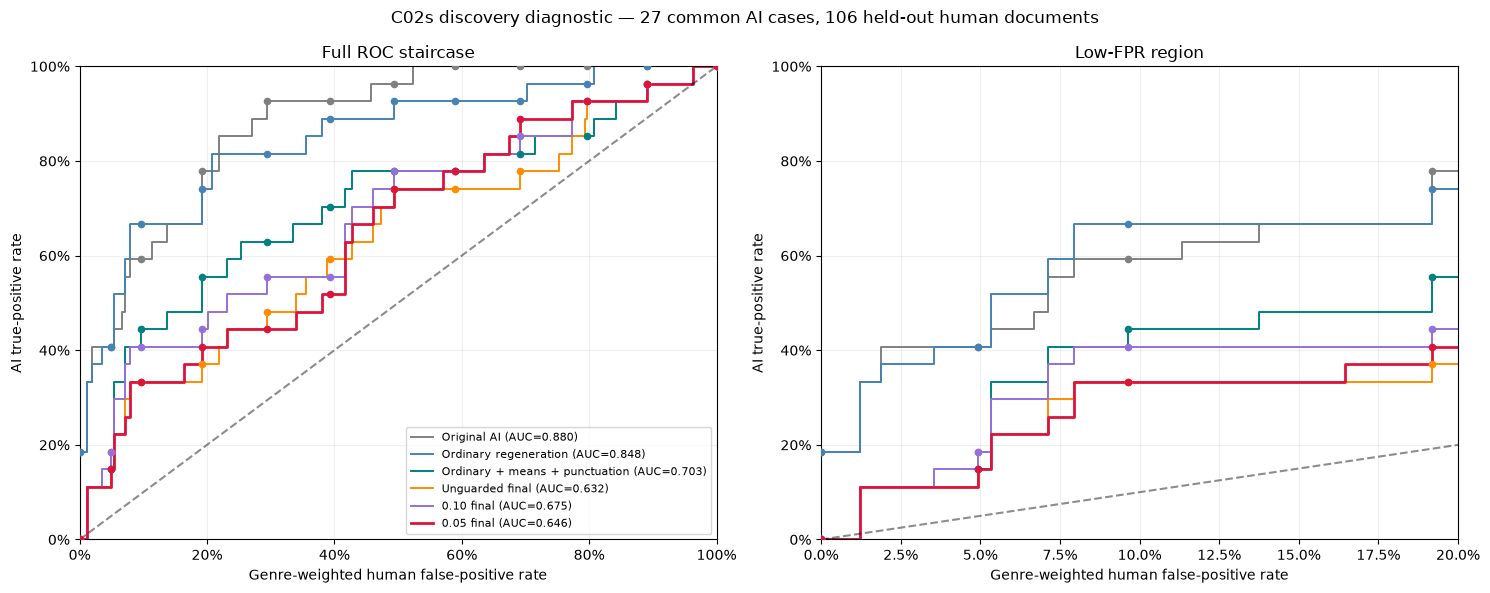

Saved: ../results/causal/C02s_relative_likelihood_sensitivity/roc_discovery
Conditional on the common downstream cohort. Discovery cases informed development; these are descriptive ROC results. Operating thresholds use human scores only, with score > threshold.


In [21]:
# C02s: ROC staircase on the same common downstream cases.
# Human thresholds are shared across every condition.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import roc_curve, roc_auc_score

roc_dir = OUT / "roc_discovery"
roc_dir.mkdir(parents=True, exist_ok=True)

scores = pd.read_csv(OUT / "downstream_scores.csv")
final = scores.loc[scores.stage.eq("final")].pivot(
    index="case_id", columns="arm", values="AI_score"
)
arm_order = ["ordinary", "unguarded", "ratio_010", "ratio_005"]
assert set(arm_order).issubset(final.columns)
assert final[arm_order].notna().all().all()
ids = sorted(final.index)

case_map = {c["case_id"]: c for c in cases}
assert all(case_map[cid]["partition"] == "discovery" for cid in ids)

ai_scores = {
    "Original AI": detector.predict_proba(
        frame_for([case_map[cid]["original"] for cid in ids])[model_features]
    )[:, 1],
    "Ordinary regeneration": scores.loc[
        scores.arm.eq("ordinary") & scores.stage.eq("unique")
    ].set_index("case_id").loc[ids, "AI_score"].to_numpy(),
    "Ordinary + means + punctuation": final.loc[ids, "ordinary"].to_numpy(),
    "Unguarded final": final.loc[ids, "unguarded"].to_numpy(),
    "0.10 final": final.loc[ids, "ratio_010"].to_numpy(),
    "0.05 final": final.loc[ids, "ratio_005"].to_numpy(),
}

# Held-out human documents, not the training-human intervention pools.
# Weight each genre to its share of these common AI cases.
genre_counts = pd.Series(
    [case_map[cid]["domain"] for cid in ids]
).value_counts()

human_test = features.loc[
    features.dataset.eq("raid")
    & features.split.eq("test")
    & features.label.eq(0)
    & features.domain.isin(genre_counts.index)
].copy()
assert human_test.source_id.is_unique

human_counts = human_test.groupby("domain").size()
assert all(human_counts.get(g, 0) > 0 for g in genre_counts.index)

human_test["weight"] = [
    genre_counts[g] / len(ids) / human_counts[g]
    for g in human_test.domain
]
h = detector.predict_proba(human_test[model_features])[:, 1]
hw = human_test["weight"].to_numpy(dtype=float, copy=True)
hw /= hw.sum()

assert np.isfinite(h).all()
assert all(np.isfinite(v).all() and len(v) == len(ids)
           for v in ai_scores.values())

human_test.assign(AI_score=h).to_csv(
    roc_dir / "human_scores_and_weights.csv", index=False
)
pd.DataFrame(ai_scores, index=pd.Index(ids, name="case_id")).to_csv(
    roc_dir / "AI_scores.csv"
)

# Full empirical ROC: all unique thresholds, tied scores kept together.
curves = {}
auc_rows = []
curve_rows = []
for name, a in ai_scores.items():
    labels = np.r_[np.zeros(len(h)), np.ones(len(a))]
    values = np.r_[h, a]
    weights = np.r_[hw, np.full(len(a), 1 / len(a))]
    fpr, tpr, thresholds = roc_curve(
        labels, values, sample_weight=weights, drop_intermediate=False
    )
    auc = roc_auc_score(labels, values, sample_weight=weights)
    curves[name] = (fpr, tpr)
    auc_rows.append({
        "condition": name, "ROC_AUC": auc,
        "n_AI": len(a), "n_human": len(h),
    })
    curve_rows.extend(
        {"condition": name, "FPR": x, "TPR": y, "threshold": t}
        for x, y, t in zip(fpr, tpr, thresholds)
    )

# Human-only operating thresholds.
# Classify as AI when score > threshold: this permits all scores above
# a tied human boundary without splitting that tie.
budgets = np.array([.01, .05, .10, .20, .30, .40,
                    .50, .60, .70, .80, .90, 1.])
human_thresholds = np.r_[np.unique(h)[::-1], -np.inf]
achieved = np.array([
    hw[h > threshold].sum() for threshold in human_thresholds
])

operating_rows = []
for budget in budgets:
    eligible = np.flatnonzero(achieved <= budget + 1e-12)
    j = eligible[-1]  # Most permissive human-only cutoff within budget.
    threshold = human_thresholds[j]
    row = {
        "requested_FPR": budget,
        "achieved_FPR": achieved[j],
        "threshold": threshold,
    }
    row.update({
        name: float(np.mean(a > threshold))
        for name, a in ai_scores.items()
    })
    operating_rows.append(row)

operating = pd.DataFrame(operating_rows)
auc_table = pd.DataFrame(auc_rows)
operating.to_csv(roc_dir / "TPR_at_FPR_budgets.csv", index=False)
auc_table.to_csv(roc_dir / "ROC_AUC_summary.csv", index=False)
pd.DataFrame(curve_rows).to_csv(
    roc_dir / "ROC_staircase.csv", index=False
)

display(auc_table.round(4))
display(
    operating.drop(columns="threshold")
    .mul(100)
    .rename(columns={
        "requested_FPR": "Requested FPR %",
        "achieved_FPR": "Achieved FPR %",
    })
    .round(2)
)

colors = ["gray", "steelblue", "teal", "darkorange", "mediumpurple", "crimson"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for color, (name, (fpr, tpr)) in zip(colors, curves.items()):
    auc = auc_table.set_index("condition").loc[name, "ROC_AUC"]
    for ax in axes:
        ax.step(
            fpr, tpr, where="post", color=color,
            linewidth=2 if name == "0.05 final" else 1.4,
            label=f"{name} (AUC={auc:.3f})",
        )
        ax.scatter(
            operating["achieved_FPR"], operating[name],
            color=color, s=20, zorder=3,
        )

for ax, xmax in zip(axes, [1., .20]):
    ax.plot([0, xmax], [0, xmax], "--", color="black", alpha=.45)
    ax.set_xlim(0, xmax)
    ax.set_ylim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel("Genre-weighted human false-positive rate")
    ax.set_ylabel("AI true-positive rate")
    ax.grid(alpha=.2)

axes[0].set_title("Full ROC staircase")
axes[1].set_title("Low-FPR region")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle(
    f"C02s discovery diagnostic — {len(ids)} common AI cases, "
    f"{len(h)} held-out human documents"
)
fig.tight_layout()

for ext in ("png", "pdf"):
    fig.savefig(
        roc_dir / f"ROC_staircase.{ext}",
        dpi=300, bbox_inches="tight",
    )
plt.show()

print("Saved:", roc_dir)
print(
    "Conditional on the common downstream cohort. "
    "Discovery cases informed development; these are descriptive ROC results. "
    "Operating thresholds use human scores only, with score > threshold."
)

Attributing: ordinary
Attributing: unguarded
Attributing: ratio_010
Attributing: ratio_005

27 discovery cases; fixed same-genre human reference.
Positive final_gap = remaining AI-ward contribution.
Negative change_vs_ordinary_final = reduced contribution.


,rank,feature,final_mean_contribution,human_mean_contribution,final_gap,ci_low,ci_high,fraction_cases_AIward,ordinary_final_gap,unguarded_final_gap,ratio_010_final_gap,change_vs_ordinary_final,change_ci_low,change_ci_high,final_feature_mean,human_feature_mean,raw_feature_gap
0,1,punct_relative_exclamation,0.002255,-0.003426,0.005681,0.001033,0.011352,0.629630,0.006367,0.005724,0.005814,-0.000686,-0.001789,-0.000045,0.000118,0.000013,0.000105
1,2,share_long_words,0.004120,-0.000454,0.004574,0.001792,0.007100,0.777778,0.004085,0.004655,0.004611,0.000489,-0.000285,0.001334,0.288119,0.259035,0.029084
2,3,punct_per_sentence_exclamation,0.001764,-0.002763,0.004526,0.000697,0.009269,0.518519,0.004878,0.004873,0.004589,-0.000352,-0.000895,-0.000014,0.011237,0.001617,0.009621
3,4,punct_relative_semicolon,0.000483,-0.003335,0.003818,-0.005243,0.011890,0.814815,0.005351,0.003712,0.005772,-0.001533,-0.006023,0.001065,0.000199,0.000341,-0.000142
4,5,punct_per_sentence_hyphen,0.002326,-0.000881,0.003208,0.001311,0.005102,0.740741,0.003335,0.003252,0.003085,-0.000127,-0.000817,0.000478,0.252921,0.322462,-0.069541
5,6,punct_per_sentence_period,0.001007,-0.002060,0.003067,0.000642,0.005364,0.777778,0.002855,0.002776,0.003037,0.000212,-0.000270,0.000697,1.112080,1.089636,0.022444
6,7,words_per_sentence,0.002418,-0.000442,0.002860,0.001612,0.004138,0.851852,0.003205,0.003109,0.003121,-0.000345,-0.001341,0.000482,18.817390,19.877292,-1.059901
7,8,punct_per_sentence_semicolon,0.000221,-0.002546,0.002767,-0.004575,0.009069,0.814815,0.004146,0.002738,0.004298,-0.001379,-0.004941,0.000544,0.027687,0.034115,-0.006428
8,9,smog_grade,0.002541,-0.000189,0.002730,0.001567,0.003888,0.814815,0.002937,0.002573,0.002516,-0.000207,-0.000712,0.000217,13.425958,12.748033,0.677925
9,10,punct_relative_hyphen,0.000676,-0.001963,0.002639,-0.000217,0.005079,0.703704,0.002616,0.002596,0.002130,0.000023,-0.001236,0.000968,0.002035,0.002439,-0.000404



Largest human-ward contributions relative to humans:


,feature,final_gap,ci_low,ci_high
113,punct_relative_colon,-0.006536,-0.010398,-0.003132
112,punct_per_sentence_colon,-0.003643,-0.005727,-0.001847
111,word_2gram_overlap_bin_0,-0.003418,-0.005367,-0.001323
110,pos_3gram_overlap_bin_0,-0.001953,-0.005390,0.001629
109,word_1gram_overlap_bin_0,-0.001515,-0.002984,-0.000004
108,pos_1gram_overlap_bin_2,-0.001201,-0.003846,0.000501
107,pos_2gram_overlap_bin_0,-0.001097,-0.003485,0.000879
106,pos_3gram_overlap_bin_2,-0.000760,-0.002496,0.001065
105,punct_per_sentence_question,-0.000719,-0.001300,-0.000063
104,pos_1gram_overlap_bin_5,-0.000695,-0.001812,0.000551



Mean score gap versus human reference: 0.053972
Sum of feature contribution gaps:      0.053972


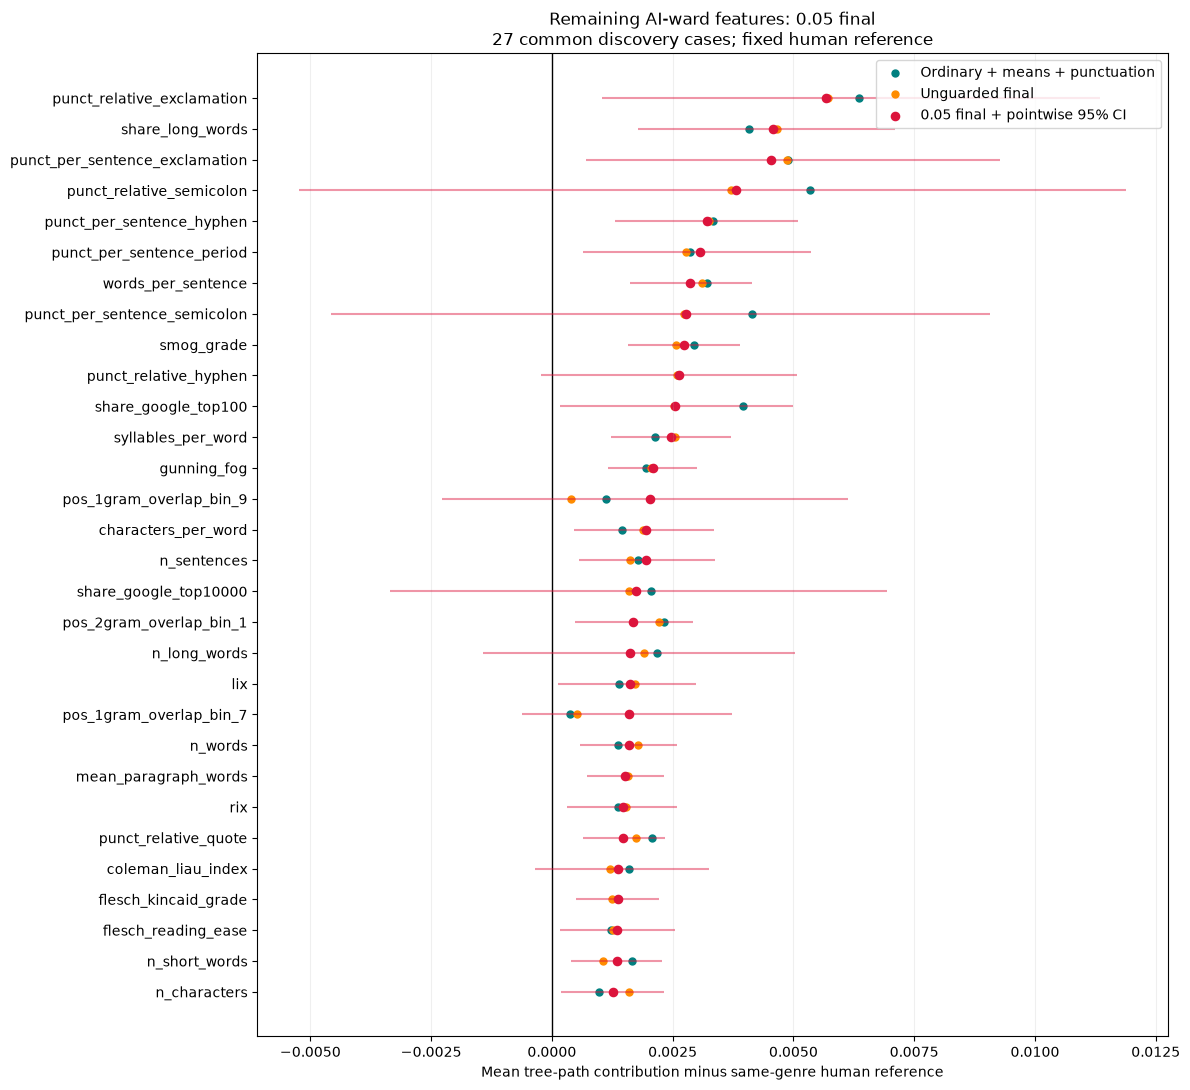

Saved: ../results/causal/C02s_relative_likelihood_sensitivity/feature_contributions_discovery


In [22]:
# Feature contributions: same common discovery cohort as the ROC.
# Reuses saved features; no generation or feature extraction is repeated.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

contrib_dir = OUT / "feature_contributions_discovery"
contrib_dir.mkdir(parents=True, exist_ok=True)

ff = pd.read_csv(OUT / "downstream_features.csv")
sf = pd.read_csv(OUT / "downstream_scores.csv")
arms = ["ordinary", "unguarded", "ratio_010", "ratio_005"]

wide = sf.loc[sf.stage.eq("final")].pivot(
    index="case_id", columns="arm", values="AI_score"
)
cids = sorted(wide.dropna(subset=arms).index)
case_lookup = {c["case_id"]: c for c in cases}
genres = [case_lookup[cid]["domain"] for cid in cids]
features = list(model_features)
assert cids and set(genres) <= set(human_test["domain"])

# Same-genre human baselines. Averaging across AI cases reproduces
# the ROC's AI-genre weighting of the human reference population.
HX = human_test[features].astype(float).reset_index(drop=True)
HC = pd.DataFrame(contributions(HX), columns=features)
hg = human_test["domain"].to_numpy()
human_c = HC.groupby(hg).mean().loc[genres].to_numpy()
human_x = HX.groupby(hg).mean().loc[genres].to_numpy()

C, X = {}, {}
for arm in arms:
    print("Attributing:", arm, flush=True)
    x = (
        ff.loc[ff.arm.eq(arm) & ff.stage.eq("final")]
        .set_index("case_id").loc[cids, features].astype(float)
    )
    X[arm] = x.to_numpy()
    C[arm] = contributions(x)

    # Check that saved features reconstruct the reported scores.
    np.testing.assert_allclose(
        detector.predict_proba(x)[:, 1],
        wide.loc[cids, arm].to_numpy(),
        atol=1e-8,
    )

# Case bootstrap, conditional on this fixed human reference.
# Chunking avoids a large bootstrap × case × feature allocation.
rng = np.random.default_rng(20260908)
boot_idx = rng.integers(len(cids), size=(3000, len(cids)))

def mean_ci(a):
    boot = np.concatenate([
        a[idx].mean(axis=1)
        for idx in np.array_split(boot_idx, 30)
    ])
    return np.quantile(boot, [0.025, 0.975], axis=0)

gap = C["ratio_005"] - human_c
lo, hi = mean_ci(gap)
delta = C["ratio_005"] - C["ordinary"]
dlo, dhi = mean_ci(delta)

ranking = pd.DataFrame({
    "feature": features,
    "final_mean_contribution": C["ratio_005"].mean(0),
    "human_mean_contribution": human_c.mean(0),
    "final_gap": gap.mean(0),
    "ci_low": lo,
    "ci_high": hi,
    "fraction_cases_AIward": (gap > 0).mean(0),
    "ordinary_final_gap": (C["ordinary"] - human_c).mean(0),
    "unguarded_final_gap": (C["unguarded"] - human_c).mean(0),
    "ratio_010_final_gap": (C["ratio_010"] - human_c).mean(0),
    "change_vs_ordinary_final": delta.mean(0),
    "change_ci_low": dlo,
    "change_ci_high": dhi,
    "final_feature_mean": X["ratio_005"].mean(0),
    "human_feature_mean": human_x.mean(0),
    "raw_feature_gap": (X["ratio_005"] - human_x).mean(0),
}).sort_values("final_gap", ascending=False).reset_index(drop=True)
ranking.insert(0, "rank", np.arange(1, len(ranking) + 1))
ranking.to_csv(contrib_dir / "all_feature_contributions.csv", index=False)

# Preserve per-case attribution values for later analysis.
case_rows = []
for arm in arms:
    for i, cid in enumerate(cids):
        for j, feature in enumerate(features):
            case_rows.append({
                "case_id": cid, "domain": genres[i], "arm": arm,
                "feature": feature,
                "contribution": C[arm][i, j],
                "human_reference_contribution": human_c[i, j],
                "gap": C[arm][i, j] - human_c[i, j],
            })
pd.DataFrame(case_rows).to_csv(
    contrib_dir / "per_case_contributions.csv", index=False
)

print(f"\n{len(cids)} discovery cases; fixed same-genre human reference.")
print("Positive final_gap = remaining AI-ward contribution.")
print("Negative change_vs_ordinary_final = reduced contribution.")
display(ranking.head(30).round(6))

print("\nLargest human-ward contributions relative to humans:")
display(ranking.nsmallest(10, "final_gap")[
    ["feature", "final_gap", "ci_low", "ci_high"]
].round(6))

# Attribution gaps must sum to the mean AI-score gap.
human_scores = detector.predict_proba(HX)[:, 1]
human_score_ref = (
    pd.Series(human_scores).groupby(hg).mean().loc[genres].to_numpy()
)
score_gap = wide.loc[cids, "ratio_005"].to_numpy() - human_score_ref
np.testing.assert_allclose(gap.sum(1), score_gap, atol=1e-8)
print(f"\nMean score gap versus human reference: {score_gap.mean():.6f}")
print(f"Sum of feature contribution gaps:      {gap.mean(0).sum():.6f}")

top = ranking.head(30).iloc[::-1]
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(12, 11))
ax.axvline(0, color="black", linewidth=1)
ax.hlines(y, top.ci_low, top.ci_high, color="crimson", alpha=.45)
ax.scatter(top.ordinary_final_gap, y, color="teal", s=25,
           label="Ordinary + means + punctuation")
ax.scatter(top.unguarded_final_gap, y, color="darkorange", s=25,
           label="Unguarded final")
ax.scatter(top.final_gap, y, color="crimson", s=35,
           label="0.05 final + pointwise 95% CI")
ax.set_yticks(y, top.feature)
ax.set_xlabel("Mean tree-path contribution minus same-genre human reference")
ax.set_title(
    f"Remaining AI-ward features: 0.05 final\n"
    f"{len(cids)} common discovery cases; fixed human reference"
)
ax.grid(axis="x", alpha=.2)
ax.legend(loc="best")
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(contrib_dir / f"remaining_feature_contributions.{ext}",
                dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", contrib_dir)

In [23]:
display(ranking.loc[
    ranking.feature.isin([
        "punct_relative_exclamation",
        "punct_per_sentence_exclamation",
        "punct_relative_period",
        "punct_per_sentence_period",
    ]),
    ["feature", "final_feature_mean", "human_feature_mean",
     "raw_feature_gap", "final_gap"]
].round(6))

,feature,final_feature_mean,human_feature_mean,raw_feature_gap,final_gap
0,punct_relative_exclamation,0.000118,0.000013,0.000105,0.005681
2,punct_per_sentence_exclamation,0.011237,0.001617,0.009621,0.004526
5,punct_per_sentence_period,1.112080,1.089636,0.022444,0.003067
45,punct_relative_period,0.009691,0.009194,0.000497,0.000303


,cases,sentence_in_band,final_in_band,pushed_out_by_punctuation,punctuation_worsened_distance,mean_sentence_distance,mean_final_distance,mean_punctuation_wps_change,mean_final_minus_training,mean_final_minus_heldout
arm,,,,,,,,,,
ordinary,27,11,13,0,3,0.87463,0.86826,0.00300,-0.18594,-0.91042
unguarded,27,17,17,0,3,0.70119,0.69458,-0.00259,-0.37251,-1.09700
ratio_010,27,16,16,0,3,0.75902,0.75459,0.00300,-0.46484,-1.18933
ratio_005,27,16,16,0,3,0.76156,0.75494,-0.00221,-0.33542,-1.05990


Sentence-stage stopping conditions:


sentence_status,in_band,no_eligible_improving_candidate
arm,,
ordinary,8,19
unguarded,13,14
ratio_010,12,15
ratio_005,12,15



0.05: cases outside the target at either stage, or with WPS drift:


,case_id,domain,sentence_status,sentence_edits,target_low,target_high,unique_wps,sentence_wps,final_wps,punctuation_wps_change,punctuation_word_change,punctuation_sentence_change,pushed_out_by_punctuation
100,gate_0085,recipes,no_eligible_improving_candidate,0,10.05455,12.35556,16.81818,16.81818,17.18182,0.36364,4,0,False
81,gate_0001,abstracts,no_eligible_improving_candidate,0,20.14286,23.60000,28.60000,28.60000,27.80000,-0.80000,-4,0,False
87,gate_0025,recipes,no_eligible_improving_candidate,0,10.21818,12.31111,15.69231,15.69231,15.69231,0.00000,0,0,False
103,gate_0089,recipes,no_eligible_improving_candidate,0,9.97391,12.31111,15.41667,15.41667,15.66667,0.25000,3,0,False
98,gate_0081,recipes,no_eligible_improving_candidate,0,10.77273,12.95556,15.66667,15.66667,15.73333,0.06667,1,0,False
82,gate_0003,news,no_eligible_improving_candidate,1,19.14118,21.37647,23.68750,22.29412,22.23529,-0.05882,-1,0,False
84,gate_0018,recipes,no_eligible_improving_candidate,1,11.72333,14.72222,15.90000,15.14286,15.14286,0.00000,0,0,False
91,gate_0051,wiki,no_eligible_improving_candidate,1,17.54359,21.42667,15.92308,17.25000,17.25000,0.00000,0,0,False
97,gate_0078,wiki,no_eligible_improving_candidate,0,18.05128,21.20545,17.91667,17.91667,17.91667,0.00000,0,0,False
85,gate_0021,wiki,no_eligible_improving_candidate,0,19.24615,23.09231,19.13333,19.13333,19.13333,0.00000,0,0,False



0.05: residuals among cases STILL inside the final target:


,final_minus_training,final_minus_heldout
count,16.00000,16.00000
mean,-1.21615,-1.94476
median,-0.96777,-1.69783


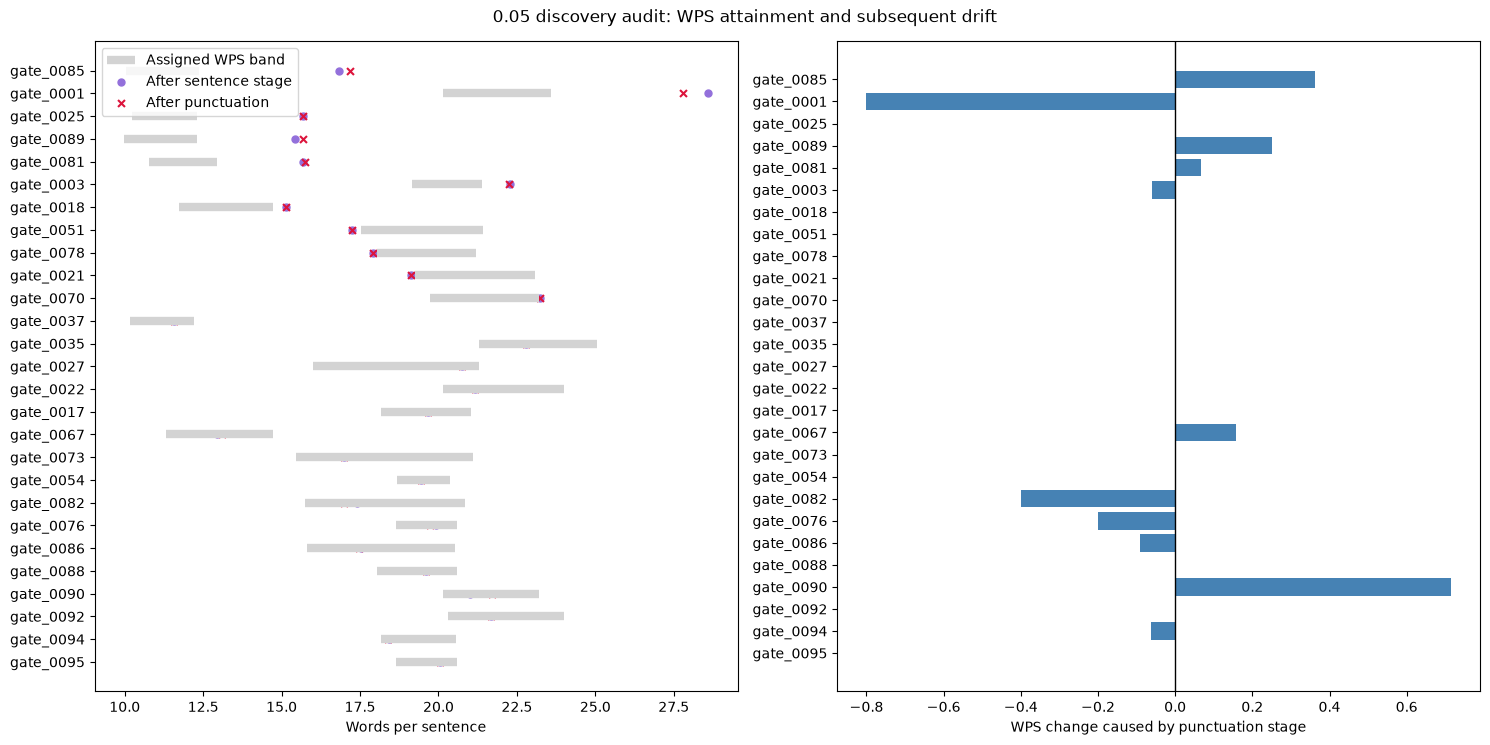

Saved: ../results/causal/C02s_relative_likelihood_sensitivity/wps_audit


In [24]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

audit_dir = OUT / "wps_audit"
audit_dir.mkdir(parents=True, exist_ok=True)

scores = pd.read_csv(OUT / "downstream_scores.csv")
arms = ["ordinary", "unguarded", "ratio_010", "ratio_005"]
wide = scores.loc[scores.stage.eq("final")].pivot(
    index="case_id", columns="arm", values="AI_score"
)
audit_ids = sorted(wide.dropna(subset=arms).index)
lookup = {c["case_id"]: c for c in cases}
TOL = 1e-9

# Held-out baseline is descriptive only; it does not define edit targets.
heldout_wps = human_test.groupby("domain")["words_per_sentence"].mean()

def band_distance(value, low, high):
    return max(low - value, value - high, 0.0)

rows = []
for arm in arms:
    for cid in audit_ids:
        saved = json.loads((OUT / cid / arm / "sentence.json").read_text())
        bounds = frozen_refs[cid]["bounds"]
        low, high = [float(bounds["wps_mean"][k]) for k in ("low", "high")]
        clow, chigh = [float(bounds["cps_mean"][k]) for k in ("low", "high")]

        stages = scores.loc[
            scores.case_id.eq(cid) & scores.arm.eq(arm)
        ].set_index("stage")
        u, s, f = [stages.loc[k] for k in ("unique", "sentence", "final")]
        refs = frozen_refs[cid]["reference_ids"]
        train_mean = np.mean([human_stats[r]["wps_mean"] for r in refs])
        genre = lookup[cid]["domain"]

        sd = band_distance(s.wps_mean, low, high)
        fd = band_distance(f.wps_mean, low, high)
        rows.append(dict(
            case_id=cid, domain=genre, arm=arm,
            sentence_status=saved["status"],
            sentence_edits=len(saved["audit"]),
            target_low=low, target_high=high,
            unique_wps=u.wps_mean,
            sentence_wps=s.wps_mean, final_wps=f.wps_mean,
            sentence_in_band=sd <= TOL,
            final_in_band=fd <= TOL,
            sentence_band_distance=sd,
            final_band_distance=fd,
            sentence_cps_in_band=(
                band_distance(s.cps_mean, clow, chigh) <= TOL
            ),
            punctuation_wps_change=f.wps_mean - s.wps_mean,
            punctuation_word_change=f.W - s.W,
            punctuation_sentence_change=f.S - s.S,
            pushed_out_by_punctuation=(sd <= TOL and fd > TOL),
            punctuation_worsened_distance=fd > sd + TOL,
            training_reference_wps=train_mean,
            heldout_genre_wps=float(heldout_wps.loc[genre]),
            final_minus_training=f.wps_mean - train_mean,
            final_minus_heldout=f.wps_mean - heldout_wps.loc[genre],
        ))

audit = pd.DataFrame(rows)
audit.to_csv(audit_dir / "per_case_wps_audit.csv", index=False)

summary = audit.groupby("arm").agg(
    cases=("case_id", "size"),
    sentence_in_band=("sentence_in_band", "sum"),
    final_in_band=("final_in_band", "sum"),
    pushed_out_by_punctuation=("pushed_out_by_punctuation", "sum"),
    punctuation_worsened_distance=("punctuation_worsened_distance", "sum"),
    mean_sentence_distance=("sentence_band_distance", "mean"),
    mean_final_distance=("final_band_distance", "mean"),
    mean_punctuation_wps_change=("punctuation_wps_change", "mean"),
    mean_final_minus_training=("final_minus_training", "mean"),
    mean_final_minus_heldout=("final_minus_heldout", "mean"),
).reindex(arms)
summary.to_csv(audit_dir / "wps_summary.csv")
display(summary.round(5))

print("Sentence-stage stopping conditions:")
display(pd.crosstab(audit.arm, audit.sentence_status).reindex(arms))

focus = audit.loc[audit.arm.eq("ratio_005")].copy()
print("\n0.05: cases outside the target at either stage, or with WPS drift:")
problem = focus.loc[
    ~focus.sentence_in_band | ~focus.final_in_band |
    focus.punctuation_wps_change.abs().gt(TOL)
].sort_values("final_band_distance", ascending=False)

display(problem[[
    "case_id", "domain", "sentence_status", "sentence_edits",
    "target_low", "target_high", "unique_wps",
    "sentence_wps", "final_wps", "punctuation_wps_change",
    "punctuation_word_change", "punctuation_sentence_change",
    "pushed_out_by_punctuation"
]].round(5))

print("\n0.05: residuals among cases STILL inside the final target:")
inside = focus.loc[focus.final_in_band]
display(inside[[
    "final_minus_training", "final_minus_heldout"
]].agg(["count", "mean", "median"]).round(5))

# Review actual sentence-stage decisions for unresolved cases.
decisions = []
for cid in focus.loc[~focus.sentence_in_band, "case_id"]:
    saved = json.loads(
        (OUT / cid / "ratio_005" / "sentence.json").read_text()
    )
    for step in saved["audit"]:
        decisions.append({
            "case_id": cid,
            "step": step["step"],
            "rule": step["rule"],
            "wps_before": step["before"]["wps_mean"],
            "wps_after": step["after"]["wps_mean"],
            "cps_before": step["before"]["cps_mean"],
            "cps_after": step["after"]["cps_mean"],
            "objective_before": step["objective_before"],
            "objective_after": step["objective_after"],
        })
pd.DataFrame(decisions).to_csv(
    audit_dir / "unresolved_case_sentence_edits.csv", index=False
)

plot = focus.sort_values("final_band_distance", ascending=False)
y = np.arange(len(plot))
fig, axes = plt.subplots(1, 2, figsize=(15, max(7, len(plot) * .28)))

axes[0].hlines(y, plot.target_low, plot.target_high,
               color="lightgray", linewidth=6, label="Assigned WPS band")
axes[0].scatter(plot.sentence_wps, y, s=25,
                color="mediumpurple", label="After sentence stage")
axes[0].scatter(plot.final_wps, y, s=25,
                color="crimson", marker="x", label="After punctuation")
axes[0].set_yticks(y, plot.case_id)
axes[0].invert_yaxis()
axes[0].set_xlabel("Words per sentence")
axes[0].legend()

axes[1].axvline(0, color="black", linewidth=1)
axes[1].barh(y, plot.punctuation_wps_change, color="steelblue")
axes[1].set_yticks(y, plot.case_id)
axes[1].invert_yaxis()
axes[1].set_xlabel("WPS change caused by punctuation stage")

fig.suptitle("0.05 discovery audit: WPS attainment and subsequent drift")
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(audit_dir / f"wps_attainment_and_drift.{ext}",
                dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", audit_dir)

[1/11] gate_0001
[2/11] gate_0003
[3/11] gate_0018
[4/11] gate_0021
[5/11] gate_0025
[6/11] gate_0051
[7/11] gate_0070
[8/11] gate_0078
[9/11] gate_0081
[10/11] gate_0085
[11/11] gate_0089


,case_id,domain,words,sentences,current_wps,target_low,target_high,wps_integer_feasible,feasible_sentence_counts,needed_direction,...,threshold,split_sites,split_sites_passing_clause_test,previously_seen,word_signature_changed,sentence_count_check,joint_objective_not_improved,score_unavailable,below_likelihood_threshold,eligible_now
0,gate_0001,abstracts,143,5,28.600000,20.142857,23.600000,True,[7],split,...,0.179304,6,0,0,0,0,4,0,0,0
1,gate_0003,news,379,17,22.294118,19.141176,21.376471,True,"[18, 19]",split,...,0.705809,9,2,0,0,0,27,0,2,0
2,gate_0018,recipes,318,21,15.142857,11.723333,14.722222,True,"[22, 23, 24, 25, 26, 27]",split,...,0.922010,24,5,0,0,10,45,0,4,0
3,gate_0021,wiki,287,15,19.133333,19.246154,23.092308,True,"[13, 14]",merge,...,0.931838,18,1,0,0,0,8,0,7,0
4,gate_0025,recipes,204,13,15.692308,10.218182,12.311111,True,"[17, 18, 19]",split,...,0.120700,13,0,0,0,0,0,0,0,0
5,gate_0051,wiki,207,12,17.250000,17.543590,21.426667,True,"[10, 11]",merge,...,0.928234,19,1,1,2,0,5,0,5,0
6,gate_0070,books,209,9,23.222222,19.727273,23.200000,True,[10],split,...,0.933400,17,3,0,0,0,20,0,3,0
7,gate_0078,wiki,215,12,17.916667,18.051282,21.205455,True,[11],merge,...,0.930863,21,4,0,0,0,36,0,8,0
8,gate_0081,recipes,235,15,15.666667,10.772727,12.955556,True,"[19, 20, 21]",split,...,0.242232,10,0,0,0,0,0,0,0,0
9,gate_0085,recipes,185,11,16.818182,10.054545,12.355556,True,"[15, 16, 17, 18]",split,...,0.070525,13,0,0,0,0,0,0,0,0



Rejections by proposed operation:


reason,below_likelihood_threshold,joint_objective_not_improved,previously_seen,sentence_count_check,word_signature_changed
rule,,,,,
boundary_shift,0,113,0,9,1
merge,20,27,0,0,1
split,9,5,1,1,0



Candidates passing all checks now (should normally be empty):


,case_id,rule,candidate,threshold,loss_before,wps_before,wps_after,cps_before,cps_after,loss_after,wps_distance_change,cps_distance_change,both_in_band,reason,mutability,score_before,score_after



Split sites excluded by the explicit-subject clause test:


,case_id,punctuation,left,right,left_passes,right_passes
0,gate_0001,",",This paper examines the issue of power flow in...,specifically focusing on situations where pow...,True,False
1,gate_0001,",",This unconventional problem has gained signifi...,"such as solar panels, into power systems.",True,False
2,gate_0001,",",This unconventional problem has gained signifi...,into power systems.,True,False
3,gate_0001,",",The study introduces a comprehensive mathemati...,including constraints on voltage and power li...,True,False
4,gate_0001,",",The study introduces a comprehensive mathemati...,and proposes an efficient solution method bas...,True,False
5,gate_0001,",",Case studies conducted in this research highli...,and pave the way for more precise and efficie...,True,False
6,gate_0003,",",Georgia's government has announced plans to in...,allowing individuals to declare any undisclos...,True,False
7,gate_0003,",",Under the proposed scheme,individuals who voluntarily disclose their hi...,False,True
8,gate_0003,",",The fine will be based on the value of the ass...,with higher penalties for larger amounts.,False,False
9,gate_0003,",",The government hopes the hidden asset pardon w...,thereby increasing tax revenues and reducing ...,True,False


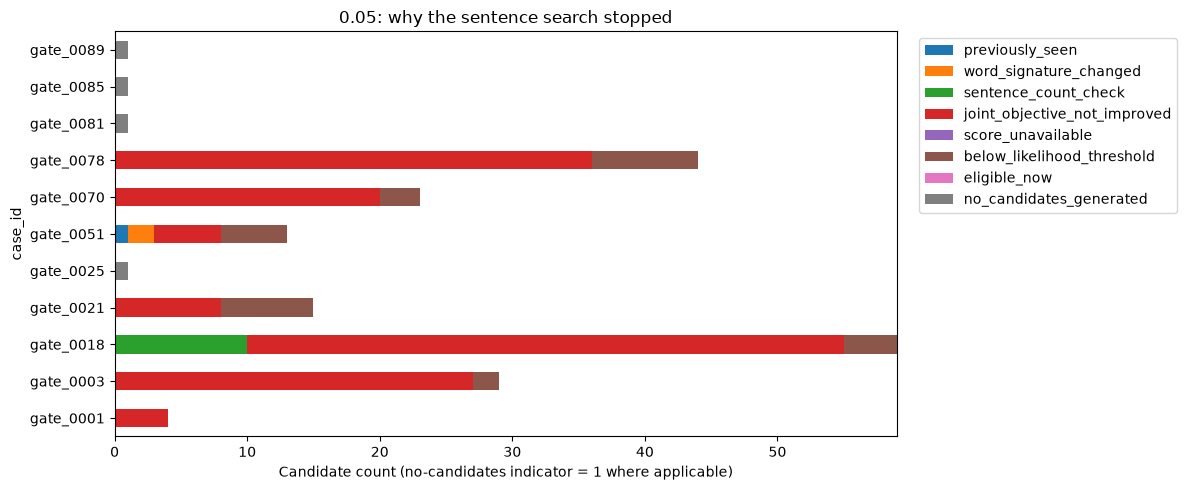

Saved: ../results/causal/C02s_relative_likelihood_sensitivity/wps_audit/rejection_diagnostic


In [25]:
# Diagnose stalled WPS search. No generation or saved-text changes.
import json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

diag_dir = OUT / "wps_audit" / "rejection_diagnostic"
diag_dir.mkdir(parents=True, exist_ok=True)

wa = pd.read_csv(OUT / "wps_audit" / "per_case_wps_audit.csv")
failed_ids = wa.loc[
    wa.arm.eq("ratio_005") & wa.sentence_band_distance.gt(1e-9),
    "case_id"
].tolist()
prepared = {
    c["case_id"]: c for c in prepared_by_arm["ratio_005"]
}

case_rows, candidate_rows, clause_rows = [], [], []
reasons = [
    "previously_seen", "word_signature_changed",
    "sentence_count_check", "joint_objective_not_improved",
    "score_unavailable", "below_likelihood_threshold", "eligible_now"
]

for number, cid in enumerate(failed_ids, 1):
    print(f"[{number}/{len(failed_ids)}] {cid}", flush=True)
    saved = json.loads(
        (OUT / cid / "ratio_005" / "sentence.json").read_text()
    )
    text = saved["text"]
    bounds = prepared[cid]["bounds"]
    stats, _ = measure(nlp(text))
    before_d = distances(stats, bounds)
    loss = float(before_d.sum())
    threshold = bar(float(before_d.max()))

    # Reconstruct the original search's visited texts.
    previous = prepared[cid]["text"]
    initial_sig = signature(previous)
    visited = {previous}
    for step in saved["audit"]:
        previous = apply_ops(previous, step["ops"])
        visited.add(previous)
    assert previous == text, f"Replay mismatch: {cid}"

    # Necessary WPS feasibility, allowing any S >= 2 with fixed W.
    # This does not prove that valid edits can reach that sentence count.
    W, S = int(stats["W"]), int(stats["S"])
    low, high = [float(bounds["wps_mean"][k]) for k in ("low", "high")]
    possible_s = [
        n for n in range(2, W + 1)
        if low - 1e-9 <= W / n <= high + 1e-9
    ]

    # Inspect comma/semicolon sites rejected BEFORE proposal generation.
    doc = nlp(text)
    sentences = [
        s for s in doc.sents if any(t.is_alpha for t in s)
    ]
    site_counts = Counter()
    for sentence in sentences:
        for token in sentence:
            if token.text not in {",", ";"}:
                continue
            left = text[sentence.start_char:token.idx]
            right = text[token.idx + 1:sentence.end_char]
            left_ok, right_ok = independent(left), independent(right)
            site_counts["split_sites"] += 1
            site_counts["split_sites_passing_clause_test"] += int(
                left_ok and right_ok
            )
            clause_rows.append(dict(
                case_id=cid, punctuation=token.text,
                left=left, right=right,
                left_passes=left_ok, right_passes=right_ok,
            ))

    counts = Counter()
    generated = 0
    for rule, ops, candidate in proposals(text):
        generated += 1
        row = dict(
            case_id=cid, rule=rule, candidate=candidate,
            threshold=threshold, loss_before=loss,
        )
        if candidate in visited:
            reason = "previously_seen"
        elif signature(candidate) != initial_sig:
            reason = "word_signature_changed"
        else:
            after, _ = measure(nlp(candidate))
            d = distances(after, bounds)
            row.update(
                wps_before=stats["wps_mean"],
                wps_after=after["wps_mean"],
                cps_before=stats["cps_mean"],
                cps_after=after["cps_mean"],
                loss_after=float(d.sum()),
                wps_distance_change=float(d[0] - before_d[0]),
                cps_distance_change=float(d[1] - before_d[1]),
                both_in_band=bool(np.all(d <= 1e-12)),
            )
            expected = {"split": 1, "merge": -1, "boundary_shift": 0}[rule]
            if after["S"] != S + expected or after["S"] < 2:
                reason = "sentence_count_check"
            elif d.sum() >= loss - 1e-10:
                reason = "joint_objective_not_improved"
            else:
                a = min(o[0] for o in ops)
                b = max(o[1] for o in ops)
                replacement = apply_ops(
                    text[a:b], [(x-a, y-a, r) for x, y, r in ops]
                )
                score = score_edit(text, dict(
                    start=a, end=b, replacement=replacement
                ))
                if score is None:
                    reason = "score_unavailable"
                else:
                    row.update(score)
                    reason = (
                        "below_likelihood_threshold"
                        if score["mutability"] < threshold
                        else "eligible_now"
                    )
        row["reason"] = reason
        counts[reason] += 1
        candidate_rows.append(row)

    case_rows.append(dict(
        case_id=cid, domain=prepared[cid]["domain"],
        words=W, sentences=S, current_wps=stats["wps_mean"],
        target_low=low, target_high=high,
        wps_integer_feasible=bool(possible_s),
        feasible_sentence_counts=json.dumps(possible_s),
        needed_direction=(
            "split" if stats["wps_mean"] > high else "merge"
        ),
        generated_candidates=generated,
        threshold=threshold,
        **site_counts,
        **{reason: counts[reason] for reason in reasons},
    ))

cases_diag = pd.DataFrame(case_rows)
candidates_diag = pd.DataFrame(candidate_rows)
clauses_diag = pd.DataFrame(clause_rows)

cases_diag.to_csv(diag_dir / "case_rejection_summary.csv", index=False)
candidates_diag.to_csv(diag_dir / "candidate_rejections.csv", index=False)
clauses_diag.to_csv(diag_dir / "split_clause_checks.csv", index=False)

display(cases_diag)
if not candidates_diag.empty:
    print("\nRejections by proposed operation:")
    display(pd.crosstab(candidates_diag.rule, candidates_diag.reason))

    print("\nCandidates passing all checks now (should normally be empty):")
    display(candidates_diag.loc[
        candidates_diag.reason.eq("eligible_now")
    ])

print("\nSplit sites excluded by the explicit-subject clause test:")
if not clauses_diag.empty:
    blocked = clauses_diag.loc[
        ~clauses_diag.left_passes | ~clauses_diag.right_passes
    ]
    display(blocked.head(20))

if not cases_diag.empty:
    plot_counts = cases_diag.set_index("case_id")[reasons].copy()
    plot_counts["no_candidates_generated"] = (
        cases_diag.set_index("case_id").generated_candidates.eq(0).astype(int)
    )
    ax = plot_counts.plot.barh(
        stacked=True, figsize=(12, max(5, len(cases_diag) * .45))
    )
    ax.set_xlabel(
        "Candidate count (no-candidates indicator = 1 where applicable)"
    )
    ax.set_title("0.05: why the sentence search stopped")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    fig = ax.get_figure()
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(diag_dir / f"rejection_breakdown.{ext}",
                    dpi=300, bbox_inches="tight")
    plt.show()

print("Saved:", diag_dir)

expanded_only: 1/11 gate_0001
gate_0001 1 split loss= 0.0675
expanded_only: 2/11 gate_0003
expanded_only: 3/11 gate_0018
gate_0018 1 split loss= 0.0
expanded_only: 4/11 gate_0021
expanded_only: 5/11 gate_0025
gate_0025 1 split loss= 2.0697
expanded_only: 6/11 gate_0051
expanded_only: 7/11 gate_0070
expanded_only: 8/11 gate_0078
expanded_only: 9/11 gate_0081
gate_0081 1 split loss= 1.6901
expanded_only: 10/11 gate_0085
gate_0085 1 split loss= 2.2127
gate_0085 2 split loss= 1.2927
gate_0085 3 split loss= 0.5042
expanded_only: 11/11 gate_0089
lower_bar_only: 1/11 gate_0001
lower_bar_only: 2/11 gate_0003
gate_0003 1 split loss= 0.3053
gate_0003 2 split loss= 0.0
lower_bar_only: 3/11 gate_0018
gate_0018 1 split loss= 0.0
lower_bar_only: 4/11 gate_0021
gate_0021 1 merge loss= 0.0
lower_bar_only: 5/11 gate_0025
lower_bar_only: 6/11 gate_0051
gate_0051 1 merge loss= 0.0
lower_bar_only: 7/11 gate_0070
gate_0070 1 split loss= 0.0
lower_bar_only: 8/11 gate_0078
gate_0078 1 merge loss= 0.0
lower_b

,cases,wps_in_band,both_in_band,mean_edits,mean_wps_distance,mean_joint_distance
variant,,,,,,
expanded_lower,11,6,6,1.181818,0.331169,0.611423
expanded_only,11,1,1,0.636364,0.382491,0.734734
lower_bar_only,11,6,6,0.636364,0.688364,1.234703


,case_id,variant,status,edits,wps_before,wps_after,cps_before,cps_after,wps_in_band,both_in_band,wps_distance_before,wps_distance_after,joint_distance_before,joint_distance_after
0,gate_0001,expanded_only,no_eligible_improving_candidate,1,28.60000,23.83333,194.80000,162.16667,False,False,1.44628,0.06749,2.29154,0.06749
1,gate_0003,expanded_only,no_eligible_improving_candidate,0,22.29412,22.29412,145.88235,145.88235,False,False,0.41053,0.41053,1.16355,1.16355
2,gate_0018,expanded_only,in_band,1,15.14286,14.45455,85.95238,82.00000,True,True,0.14026,0.00000,0.14026,0.00000
3,gate_0021,expanded_only,no_eligible_improving_candidate,0,19.13333,19.13333,128.66667,128.66667,False,False,0.02933,0.02933,0.02933,0.02933
4,gate_0025,expanded_only,no_eligible_improving_candidate,1,15.69231,14.57143,102.76923,95.35714,False,False,1.61553,1.07998,3.02825,2.06970
5,gate_0051,expanded_only,no_eligible_improving_candidate,0,17.25000,17.25000,104.16667,104.16667,False,False,0.07561,0.07561,0.11446,0.11446
6,gate_0070,expanded_only,no_eligible_improving_candidate,0,23.22222,23.22222,137.22222,137.22222,False,False,0.00640,0.00640,0.00640,0.00640
7,gate_0078,expanded_only,no_eligible_improving_candidate,0,17.91667,17.91667,111.91667,111.91667,False,False,0.04268,0.04268,0.04268,0.04268
8,gate_0081,expanded_only,no_eligible_improving_candidate,1,15.66667,14.68750,98.66667,92.43750,False,False,1.24202,0.79344,2.56787,1.69015
9,gate_0085,expanded_only,no_eligible_improving_candidate,3,16.81818,13.21429,102.72727,80.50000,False,False,1.93942,0.37320,3.29995,0.50418


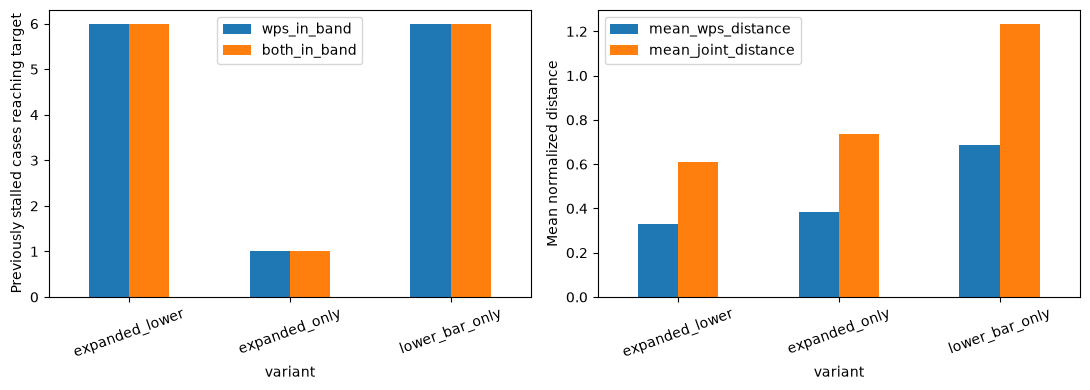

Saved: ../results/causal/C02s_relative_likelihood_sensitivity/wps_repair_v1


In [26]:
import json
import re
import numpy as np
import pandas as pd

repair_dir = OUT / "wps_repair_v1"
repair_dir.mkdir(parents=True, exist_ok=True)

# Capture the original functions once, so rerunning this cell is safe.
if "_wps_original_proposals" not in globals():
    _wps_original_proposals = proposals
    _wps_original_bar = bar

def imperative_clause(text):
    """Conservative heuristic for subjectless instructions, e.g. 'Stir well'."""
    doc = nlp(text.strip())
    roots = [t for t in doc if t.dep_ == "ROOT"]
    if len(roots) != 1:
        return False
    root = roots[0]
    if root.pos_ != "VERB" or root.tag_ != "VB":
        return False
    if any(t.dep_ in {"nsubj", "nsubjpass", "csubj", "expl"} for t in root.children):
        return False
    # Avoid treating subordinate clauses as standalone instructions.
    if any(t.dep_ == "mark" for t in root.children):
        return False
    return True

def standalone_clause(text):
    return independent(text) or imperative_clause(text)

def expanded_proposals(text):
    # Preserve every original candidate.
    seen = set()
    for rule, ops, candidate in _wps_original_proposals(text):
        seen.add(candidate)
        yield rule, ops, candidate

    doc = nlp(text)
    sentences = [s for s in doc.sents if any(t.is_alpha for t in s)]
    added = []

    for sentence in sentences:
        for token in sentence:
            if token.text not in {",", ";"}:
                continue
            left = text[sentence.start_char:token.idx]
            right = text[token.idx + 1:sentence.end_char]
            if not (standalone_clause(left) and standalone_clause(right)):
                continue
            match = re.search(r"[A-Za-z]", right)
            if match:
                j = token.idx + 1 + match.start()
                added.append(("split", [
                    (token.idx, token.idx + 1, "."),
                    (j, j + 1, text[j].upper()),
                ]))

    for left, right in zip(sentences, sentences[1:]):
        end = left.end_char
        if text[end - 1:end] != ".":
            continue
        # Preserve paragraph boundaries.
        gap = text[end:right.start_char]
        if gap.strip() or "\n" in gap:
            continue
        if standalone_clause(left.text[:-1]) and standalone_clause(right.text):
            added.append(("merge", [(end - 1, end, ";")]))

    for rule, ops in added:
        candidate = apply_ops(text, ops)
        if candidate not in seen:
            seen.add(candidate)
            yield rule, ops, candidate

def reduced_bar(q):
    return max(0.05, 0.5 * _wps_original_bar(q))

variants = {
    "expanded_only": (expanded_proposals, _wps_original_bar),
    "lower_bar_only": (_wps_original_proposals, reduced_bar),
    "expanded_lower": (expanded_proposals, reduced_bar),
}

failed_ids = wa.loc[
    wa.arm.eq("ratio_005") & wa.sentence_band_distance.gt(1e-9),
    "case_id"
].tolist()
prepared = {c["case_id"]: c for c in prepared_by_arm["ratio_005"]}

rows, reviews = [], []
saved_proposals, saved_bar = proposals, bar

try:
    for variant, (proposal_fn, bar_fn) in variants.items():
        proposals, bar = proposal_fn, bar_fn

        for i, cid in enumerate(failed_ids, 1):
            print(f"{variant}: {i}/{len(failed_ids)} {cid}", flush=True)
            baseline = json.loads(
                (OUT / cid / "ratio_005" / "sentence.json").read_text()
            )
            before = baseline["text"]
            c = {**prepared[cid], "text": before}

            # Run a fresh continuation of sentence editing.
            result = run_case(c)
            after = result["text"]
            before_stats = stats_for(before)
            after_stats = stats_for(after)
            bd = distances(before_stats, c["bounds"])
            ad = distances(after_stats, c["bounds"])

            assert signature(before) == signature(after)

            # Explicitly distinguish these exploratory results from parent runs.
            record = {
                "variant": variant,
                "case_id": cid,
                "parent_contract_hash": baseline["contract_hash"],
                "bar_policy": (
                    "original" if variant == "expanded_only"
                    else "max(0.05, 0.5 * original_bar(q))"
                ),
                "result": result,
            }
            (repair_dir / f"{cid}_{variant}.json").write_text(
                json.dumps(record, indent=2, ensure_ascii=False)
            )

            rows.append(dict(
                case_id=cid, variant=variant,
                status=result["status"],
                edits=len(result["audit"]),
                wps_before=before_stats["wps_mean"],
                wps_after=after_stats["wps_mean"],
                cps_before=before_stats["cps_mean"],
                cps_after=after_stats["cps_mean"],
                wps_in_band=bool(ad[0] <= 1e-12),
                both_in_band=bool(np.all(ad <= 1e-12)),
                wps_distance_before=float(bd[0]),
                wps_distance_after=float(ad[0]),
                joint_distance_before=float(bd.sum()),
                joint_distance_after=float(ad.sum()),
            ))
            reviews.append(dict(
                case_id=cid, variant=variant,
                before=before, after=after,
                grammar_acceptable="", meaning_preserved="", notes="",
            ))
finally:
    proposals, bar = saved_proposals, saved_bar

repair = pd.DataFrame(rows)
repair.to_csv(repair_dir / "repair_metrics.csv", index=False)
review_path = repair_dir / "manual_review.csv"
if not review_path.exists():
    pd.DataFrame(reviews).to_csv(review_path, index=False)

summary = repair.groupby("variant").agg(
    cases=("case_id", "size"),
    wps_in_band=("wps_in_band", "sum"),
    both_in_band=("both_in_band", "sum"),
    mean_edits=("edits", "mean"),
    mean_wps_distance=("wps_distance_after", "mean"),
    mean_joint_distance=("joint_distance_after", "mean"),
)
display(summary)
display(repair.round(5))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
summary[["wps_in_band", "both_in_band"]].plot.bar(ax=axes[0])
axes[0].set_ylabel("Previously stalled cases reaching target")
summary[["mean_wps_distance", "mean_joint_distance"]].plot.bar(ax=axes[1])
axes[1].set_ylabel("Mean normalized distance")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(repair_dir / f"repair_comparison.{ext}",
                dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", repair_dir)

1/27 gate_0001
gate_0001 colon loss 0.0
gate_0001 hyphen loss 1
gate_0001 comma loss 0
2/27 gate_0003
gate_0003 colon loss 0.0
gate_0003 hyphen loss 0.0
gate_0003 comma loss 0.0
3/27 gate_0017
4/27 gate_0018
gate_0018 colon loss 0.08333
gate_0018 hyphen loss 0.0
gate_0018 comma loss 0.0
5/27 gate_0021
gate_0021 colon loss 0.0
gate_0021 hyphen loss 0.0
gate_0021 comma loss 0.0
6/27 gate_0022
7/27 gate_0025
gate_0025 colon loss 0.0
gate_0025 hyphen loss 0.0
gate_0025 comma loss 0.0
8/27 gate_0027
9/27 gate_0035
10/27 gate_0037
11/27 gate_0051
gate_0051 colon loss 0.0
gate_0051 hyphen loss 0.0
gate_0051 comma loss 0.0
12/27 gate_0054
13/27 gate_0067
14/27 gate_0070
gate_0070 colon loss 1
gate_0070 hyphen loss 2
gate_0070 comma loss 0.0
15/27 gate_0073
16/27 gate_0076
17/27 gate_0078
gate_0078 colon loss 0.0
gate_0078 hyphen loss 0.0
gate_0078 comma loss 0.0
18/27 gate_0081
gate_0081 colon loss 0.0
gate_0081 hyphen loss 8.25908
gate_0081 comma loss 0.0
19/27 gate_0082
20/27 gate_0085
gate_

,mean_AI_score
0.05 final,0.493619
WPS repair + punctuation,0.479056
Plus exclamation,0.468876


,comparison,mean_change,ci_low,ci_high,cases_decreased
0,WPS repair + punctuation minus 0.05 final,-0.014563,-0.034259,0.000773,8
1,Plus exclamation minus 0.05 final,-0.024743,-0.044544,-0.007652,11


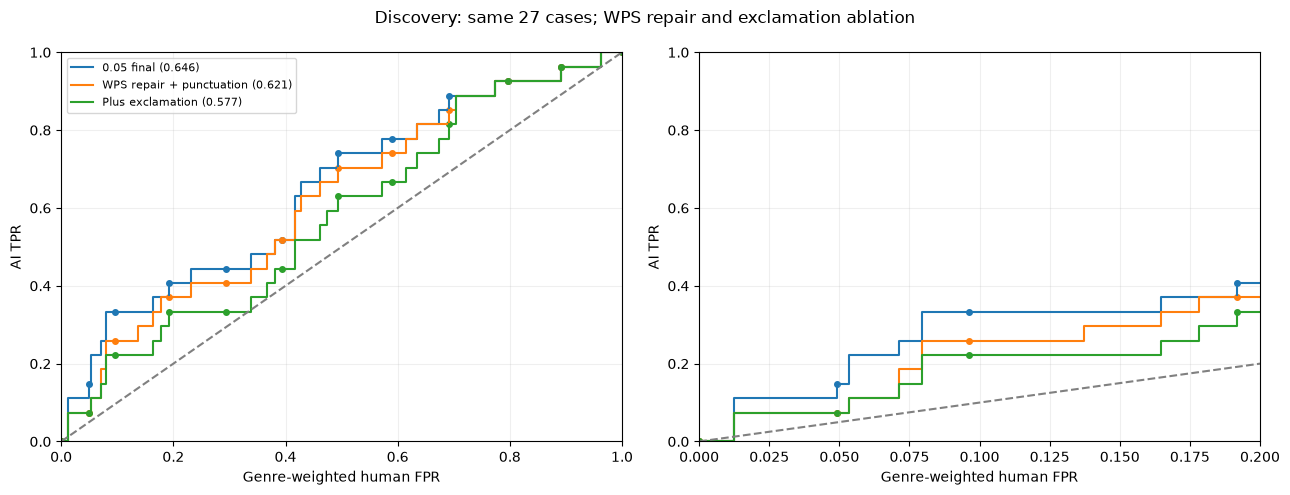

,condition,ROC_AUC
0,0.05 final,0.645872
1,WPS repair + punctuation,0.620984
2,Plus exclamation,0.577459


,requested_FPR,achieved_FPR,0.05 final,WPS repair + punctuation,Plus exclamation
0,1.0,0.00,0.00,0.00,0.00
1,5.0,4.92,14.81,7.41,7.41
2,10.0,9.63,33.33,25.93,22.22
3,20.0,19.18,40.74,37.04,33.33
4,30.0,29.41,44.44,40.74,33.33
5,40.0,39.32,51.85,51.85,44.44
6,50.0,49.33,74.07,70.37,62.96
7,60.0,59.01,77.78,74.07,66.67
8,70.0,69.08,88.89,85.19,81.48
9,80.0,79.70,92.59,92.59,92.59


,feature,0.05 final,WPS repair + punctuation,Plus exclamation,ci_low,ci_high,change_vs_old,fraction_cases_AIward
12,share_long_words,0.004574,0.004402,0.004273,0.001506,0.006741,-0.000301,0.777778
44,punct_per_sentence_hyphen,0.003208,0.003556,0.003623,0.001901,0.005274,0.000415,0.888889
33,punct_relative_hyphen,0.002639,0.002837,0.003047,0.000188,0.005466,0.000408,0.814815
39,punct_per_sentence_period,0.003067,0.003177,0.003045,0.000531,0.005335,-0.000022,0.777778
9,words_per_sentence,0.002860,0.002550,0.002776,0.001662,0.003927,-0.000084,0.888889
24,share_google_top100,0.002555,0.002729,0.002548,0.000165,0.004965,-0.000006,0.740741
21,smog_grade,0.002730,0.002464,0.002435,0.001285,0.003530,-0.000295,0.740741
8,syllables_per_word,0.002472,0.002495,0.002434,0.001146,0.003711,-0.000037,0.777778
26,share_google_top10000,0.001734,0.002132,0.002212,-0.003148,0.007693,0.000478,0.555556
111,and_conjunction_word_unigram_overlap,0.001090,0.001989,0.001947,-0.001072,0.005008,0.000857,0.592593


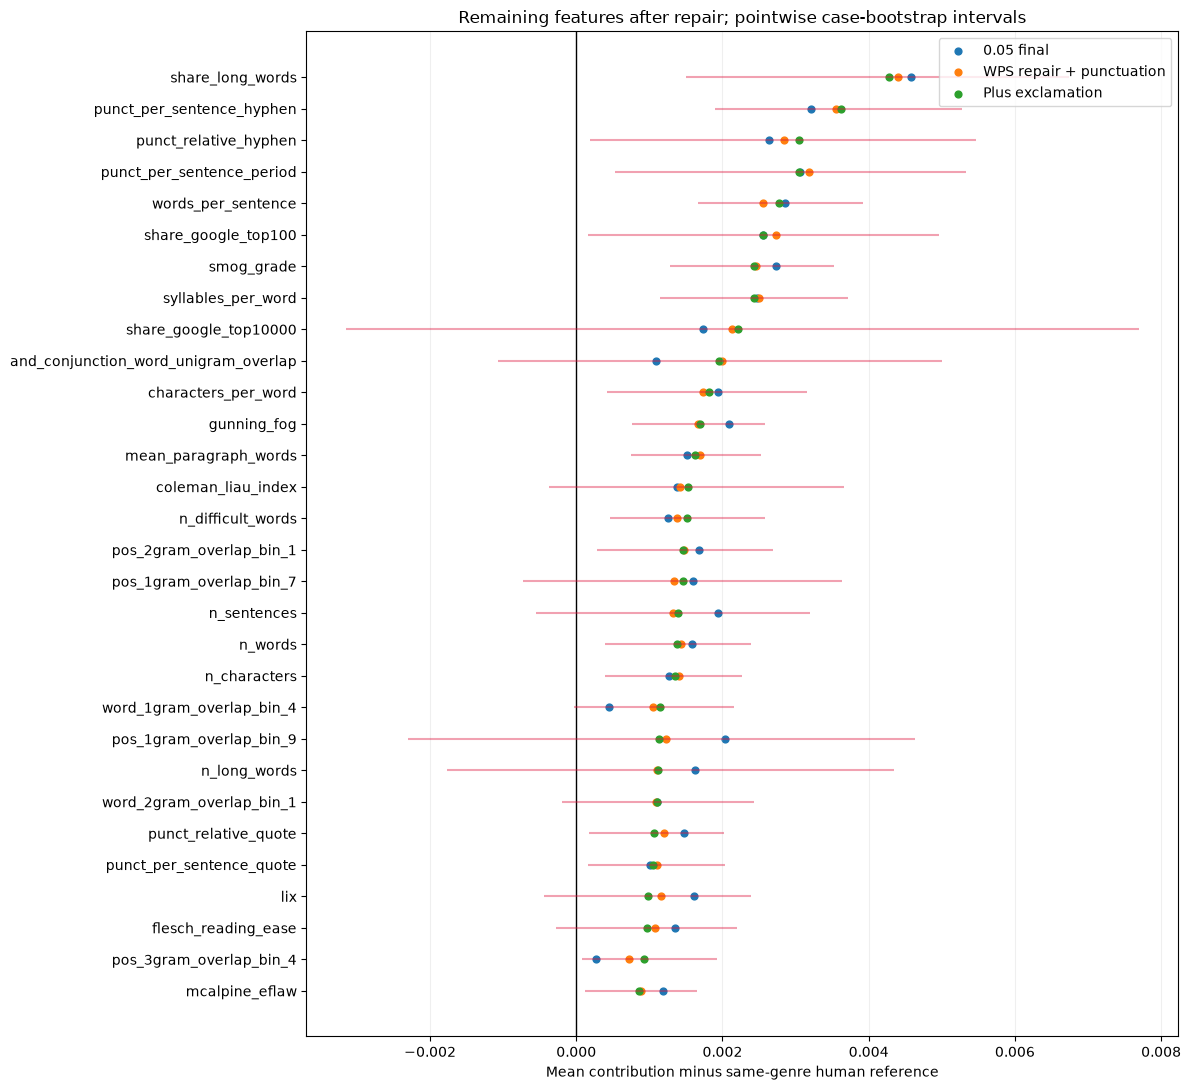

,case_id,exclamation_edits,exclamation_loss,exclamations_before,exclamations_after
0,gate_0001,0,0.0,0,0
1,gate_0003,0,0.0,0,0
2,gate_0017,0,0.0,0,0
3,gate_0018,0,0.0,0,0
4,gate_0021,0,0.0,0,0
5,gate_0022,0,0.0,0,0
6,gate_0025,0,0.0,0,0
7,gate_0027,0,0.0,0,0
8,gate_0035,0,0.0,0,0
9,gate_0037,1,0.0,1,0


Saved: ../results/causal/C02s_relative_likelihood_sensitivity/wps_repair_v1/downstream_v1


In [27]:
import copy
import hashlib
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

NEW = OUT / "wps_repair_v1" / "downstream_v1"
NEW.mkdir(parents=True, exist_ok=True)

old_cases = {
    p["case"]["case_id"]: (p, r)
    for p, r in final_by_arm["ratio_005"]
}
ids_new = sorted(old_cases)
assert len(ids_new) == 27
names = ["0.05 final", "WPS repair + punctuation", "Plus exclamation"]
text_rows, edit_reviews, target_rows = [], [], []

def cached_run(path, specification, fn):
    key = hashlib.sha256(
        json.dumps(specification, sort_keys=True, default=str).encode()
    ).hexdigest()
    if path.exists():
        payload = json.loads(path.read_text())
        assert payload["key"] == key, (
            f"Configuration changed: use a new output directory: {path}"
        )
        return payload["result"]
    result = fn()
    path.write_text(json.dumps(
        {"key": key, "result": result}, indent=2, ensure_ascii=False
    ))
    return result

def rebuild_targets(old_p, text):
    # Recompute exposure-dependent targets with the original RNG keys.
    p = copy.deepcopy(old_p)
    p["text"] = text
    p["initial"] = stats_for(text)
    p["targets"] = {}
    for mark, ds in active.items():
        if not ds:
            continue
        probabilities = []
        for denominator in ds:
            lo, hi = p["local"][mark, denominator]
            g = genre_ref[p["case"]["domain"], mark, denominator]
            trigger = (
                (g["direction"] > 0 and lo > g["hi"]) or
                (g["direction"] < 0 and hi < g["lo"])
            )
            distance = max(g["lo"] - hi, lo - g["hi"], 0) / max(
                g["sd"], abs(g["mean"]) * 1e-6, 1e-12
            )
            probabilities.append(
                BUMP_P_MIN + (1-BUMP_P_MIN)/(1+distance)
                if trigger else 0.
            )
        rng = stable_rng("target", p["case"]["case_id"], mark)
        bumped = rng.random() < max(probabilities)
        basis = "per_sentence" if "per_sentence" in ds else "relative"
        exposure = p["initial"]["S" if basis == "per_sentence" else "C"]
        expected = genre_ref[p["case"]["domain"], mark, basis]["mean"] * exposure
        p["targets"][mark] = (
            int(np.floor(expected) + (rng.random() < expected % 1))
            if bumped else None
        )
    return p

def terminal_swaps(text):
    # Only a standalone terminal punctuation token; skip initials,
    # abbreviations attached to tokens, ellipses and mixed punctuation.
    for sent in nlp(text).sents:
        tokens = [t for t in sent if not t.is_space]
        while tokens and tokens[-1].text in {'"', "'", "”", "’", ")", "]"}:
            tokens.pop()
        if not tokens or tokens[-1].text not in {".", "!"}:
            continue
        t = tokens[-1]
        a = t.idx
        if (a and text[a-1] in ".?!") or text[a+1:a+2] in {".", "?", "!"}:
            continue
        if t.text == "." and len(tokens) > 1:
            prev = tokens[-2]
            if prev.is_alpha and len(prev.text) == 1:
                continue
        yield dict(start=a, end=a+1,
                   replacement="." if t.text == "!" else "!")

def fix_exclamation(text, refs):
    # Local training-reference bands, with no held-out-human targeting.
    hr = []
    for sid in refs:
        t = normalize(text_map[sid])
        st = stats_for(t)
        hr.append([t.count("!") / st["C"], t.count("!") / st["S"]])
    bands = np.quantile(np.asarray(hr), [.2, .6], axis=0)
    initial = stats_for(text)

    def loss(t):
        st = stats_for(t)
        values = [t.count("!") / st["C"], t.count("!") / st["S"]]
        exposures = [initial["C"], initial["S"]]
        return sum(
            outside(v, bands[0, j], bands[1, j]) /
            max(bands[1, j] - bands[0, j], 1/exposures[j])
            for j, v in enumerate(values)
        )

    edits = []
    while loss(text) > 1e-10:
        candidates = []
        before_doc = nlp(text)
        sentence_words = [
            signature(s.text) for s in before_doc.sents
            if any(t.is_alpha for t in s)
        ]
        for e in terminal_swaps(text):
            candidate = text[:e["start"]] + e["replacement"] + text[e["end"]:]
            if signature(candidate) != signature(text):
                continue
            # Preserve the word membership of each sentence, not just S.
            after_sentences = [
                signature(s.text) for s in nlp(candidate).sents
                if any(t.is_alpha for t in s)
            ]
            if after_sentences != sentence_words:
                continue
            st = stats_for(candidate)
            if any(st[k] != initial[k] for k in ("W", "S", "C")):
                continue
            gain = loss(text) - loss(candidate)
            if gain <= 1e-10:
                continue
            score = score_edit(text, e)
            if score is None:
                continue
            # Same relaxed sentence-score policy; not the generation ratio.
            threshold = reduced_bar(loss(text))
            if score["mutability"] < threshold:
                continue
            candidates.append((score["mutability"], gain, candidate, e, score))
        if not candidates:
            break
        candidates.sort(key=lambda x: (-x[0], -x[1], x[2]))
        _, _, candidate, e, score = candidates[0]
        edits.append(dict(before=text, after=candidate, edit=e, **score))
        text = candidate
    return dict(text=text, edits=edits, loss=loss(text),
                bands=bands.tolist())

for i, cid in enumerate(ids_new, 1):
    print(f"{i}/{len(ids_new)} {cid}", flush=True)
    old_p, old_r = old_cases[cid]
    repair_path = OUT / "wps_repair_v1" / f"{cid}_expanded_lower.json"
    sentence_text = (
        json.loads(repair_path.read_text())["result"]["text"]
        if repair_path.exists() else old_p["text"]
    )
    p = rebuild_targets(old_p, sentence_text)

    if sentence_text == old_p["text"]:
        punct = old_r
    else:
        punct = cached_run(
            NEW / f"{cid}_punctuation.json",
            dict(text=sentence_text, targets=p["targets"],
                 local=repr(p["local"]), active=active,
                 parent=CONTRACT_HASH),
            lambda: enforce(p),
        )

    ex = cached_run(
        NEW / f"{cid}_exclamation.json",
        dict(text=punct["text"], refs=p["case"]["reference_ids"],
             policy="local_q20_q60_terminal_swap_half_bar_v1"),
        lambda: fix_exclamation(
            punct["text"], p["case"]["reference_ids"]
        ),
    )
    for condition, text in zip(names, [old_r["text"], punct["text"], ex["text"]]):
        text_rows.append(dict(
            case_id=cid, domain=p["case"]["domain"],
            condition=condition, text=text
        ))
    edit_reviews.append(dict(
        case_id=cid, original_final=old_r["text"],
        repaired_final=punct["text"], exclamation_final=ex["text"],
        grammar_acceptable="", meaning_preserved="", tone_acceptable="", notes=""
    ))
    target_rows.append(dict(
        case_id=cid, exclamation_edits=len(ex["edits"]),
        exclamation_loss=ex["loss"],
        exclamations_before=punct["text"].count("!"),
        exclamations_after=ex["text"].count("!"),
    ))

texts_new = pd.DataFrame(text_rows)
texts_new.to_csv(NEW / "texts.csv", index=False)
pd.DataFrame(target_rows).to_csv(NEW / "exclamation_audit.csv", index=False)
if not (NEW / "manual_review.csv").exists():
    pd.DataFrame(edit_reviews).to_csv(NEW / "manual_review.csv", index=False)

# Score and attribute the three conditions.
score_arrays, contribution_arrays = {}, {}
feature_tables = []
for name in names:
    print("Scoring and attributing:", name, flush=True)
    subset = texts_new.loc[texts_new.condition.eq(name)].set_index("case_id").loc[ids_new]
    x = frame_for(subset.text.tolist())[model_features]
    score_arrays[name] = detector.predict_proba(x)[:, 1]
    contribution_arrays[name] = contributions(x)
    feature_tables.append(
        x.assign(case_id=ids_new, condition=name)
    )
pd.concat(feature_tables).to_csv(NEW / "features.csv", index=False)
score_table = pd.DataFrame(score_arrays, index=ids_new)
score_table.index.name = "case_id"
score_table.to_csv(NEW / "AI_scores.csv")

# Use the same human documents and genre weighting as the ROC.
HX = human_test[model_features].astype(float)
h = detector.predict_proba(HX)[:, 1]
case_genres = [old_cases[cid][0]["case"]["domain"] for cid in ids_new]
mix = pd.Series(case_genres).value_counts(normalize=True)
human_counts = human_test.domain.value_counts()
hw = np.array([mix[g] / human_counts[g] for g in human_test.domain], float)
hw = hw / hw.sum()

rng = np.random.default_rng(20260908)
bi = rng.integers(len(ids_new), size=(3000, len(ids_new)))
changes = []
for name in names[1:]:
    d = score_arrays[name] - score_arrays[names[0]]
    b = d[bi].mean(1)
    changes.append(dict(
        comparison=f"{name} minus {names[0]}",
        mean_change=d.mean(),
        ci_low=np.quantile(b, .025), ci_high=np.quantile(b, .975),
        cases_decreased=int((d < -1e-10).sum()),
    ))
display(score_table.mean().rename("mean_AI_score").to_frame())
display(pd.DataFrame(changes))
pd.DataFrame(changes).to_csv(NEW / "paired_score_changes.csv", index=False)

budgets = np.array([.01, .05, .10, .20, .30, .40, .50, .60, .70, .80, .90, 1.])
cuts = np.r_[np.unique(h)[::-1], -np.inf]
human_fpr = np.array([hw[h > t].sum() for t in cuts])
chosen = [np.flatnonzero(human_fpr <= q + 1e-12)[-1] for q in budgets]
op = pd.DataFrame({
    "requested_FPR": budgets, "achieved_FPR": human_fpr[chosen],
    "threshold": cuts[chosen],
})
auc_rows, roc_rows = [], []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in names:
    a = score_arrays[name]
    y = np.r_[np.zeros(len(h)), np.ones(len(a))]
    s = np.r_[h, a]
    weights = np.r_[hw, np.full(len(a), 1/len(a))]
    fpr, tpr, thresholds = roc_curve(y, s, sample_weight=weights,
                                     drop_intermediate=False)
    auc = roc_auc_score(y, s, sample_weight=weights)
    auc_rows.append(dict(condition=name, ROC_AUC=auc))
    roc_rows.extend(dict(condition=name, FPR=f, TPR=t, threshold=q)
                    for f, t, q in zip(fpr, tpr, thresholds))
    op[name] = [(a > cut).mean() for cut in cuts[chosen]]
    for ax in axes:
        ax.step(fpr, tpr, where="post", label=f"{name} ({auc:.3f})")
        ax.scatter(op.achieved_FPR, op[name], s=16)
for ax, limit in zip(axes, [1., .2]):
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(xlim=(0, limit), ylim=(0, 1),
           xlabel="Genre-weighted human FPR", ylabel="AI TPR")
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
fig.suptitle("Discovery: same 27 cases; WPS repair and exclamation ablation")
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(NEW / f"ROC_staircase.{ext}", dpi=300, bbox_inches="tight")
plt.show()
display(pd.DataFrame(auc_rows))
display((op.drop(columns="threshold") * 100).round(2))
op.to_csv(NEW / "TPR_at_FPR_budgets.csv", index=False)
pd.DataFrame(auc_rows).to_csv(NEW / "ROC_AUC.csv", index=False)
pd.DataFrame(roc_rows).to_csv(NEW / "ROC_points.csv", index=False)

# Signed contribution gaps relative to the fixed same-genre humans.
hc = pd.DataFrame(contributions(HX), columns=model_features)
human_ref = hc.groupby(human_test.domain.to_numpy()).mean().loc[case_genres].to_numpy()
rank = pd.DataFrame({"feature": model_features})
for name in names:
    rank[name] = (contribution_arrays[name] - human_ref).mean(0)
gap = contribution_arrays[names[-1]] - human_ref
boot = np.concatenate([gap[ix].mean(1) for ix in np.array_split(bi, 30)])
rank["ci_low"], rank["ci_high"] = np.quantile(boot, [.025, .975], axis=0)
rank["change_vs_old"] = rank[names[-1]] - rank[names[0]]
rank["fraction_cases_AIward"] = (gap > 0).mean(0)
rank = rank.sort_values(names[-1], ascending=False)
rank.to_csv(NEW / "feature_contribution_ranking.csv", index=False)
display(rank.head(30).round(6))

# Exact score-gap reconstruction check.
human_score_ref = pd.Series(h).groupby(
    human_test.domain.to_numpy()
).mean().loc[case_genres].to_numpy()
np.testing.assert_allclose(
    gap.sum(1), score_arrays[names[-1]] - human_score_ref, atol=1e-8
)

top = rank.head(30).iloc[::-1]
yy = np.arange(len(top))
fig, ax = plt.subplots(figsize=(12, 11))
ax.axvline(0, color="black", linewidth=1)
ax.hlines(yy, top.ci_low, top.ci_high, color="crimson", alpha=.4)
for name in names:
    ax.scatter(top[name], yy, s=24, label=name)
ax.set_yticks(yy, top.feature)
ax.set_xlabel("Mean contribution minus same-genre human reference")
ax.set_title("Remaining features after repair; pointwise case-bootstrap intervals")
ax.legend()
ax.grid(axis="x", alpha=.2)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(NEW / f"feature_contributions.{ext}",
                dpi=300, bbox_inches="tight")
plt.show()
display(pd.DataFrame(target_rows))
print("Saved:", NEW)

In [28]:
import json
import numpy as np
import pandas as pd

hyphen_dir = NEW / "hyphen_audit"
hyphen_dir.mkdir(parents=True, exist_ok=True)

rows, stop_rows, examples = [], [], []

for cid in ids_new:
    old_p, old_r = old_cases[cid]
    repair_path = OUT / "wps_repair_v1" / f"{cid}_expanded_lower.json"
    sentence_text = (
        json.loads(repair_path.read_text())["result"]["text"]
        if repair_path.exists() else old_p["text"]
    )
    p = rebuild_targets(old_p, sentence_text)

    punct_path = NEW / f"{cid}_punctuation.json"
    punct = (
        json.loads(punct_path.read_text())["result"]
        if punct_path.exists() else old_r
    )
    final_text = texts_new.loc[
        texts_new.case_id.eq(cid) &
        texts_new.condition.eq("Plus exclamation"), "text"
    ].item()

    st = stats_for(final_text)
    count = final_text.count("-")
    target = p["targets"]["hyphen"]
    local = p["local"]
    loss = mark_loss(final_text, p, "hyphen")

    row = dict(
        case_id=cid, domain=p["case"]["domain"],
        hyphens=count, target_count=target,
        loss=loss, met=loss <= 1e-10,
        words=st["W"], sentences=st["S"], characters=st["C"],
    )
    for d in active["hyphen"]:
        exposure = st["C"] if d == "relative" else st["S"]
        lo, hi = local["hyphen", d]
        row.update({
            f"{d}_rate": count / exposure,
            f"{d}_low": lo,
            f"{d}_high": hi,
        })

    # Integer counts that satisfy the fixed target or both local bands.
    if target is not None:
        feasible = [int(target)]
    else:
        lower, upper = 0, float("inf")
        for d in active["hyphen"]:
            exposure = st["C"] if d == "relative" else st["S"]
            lo, hi = local["hyphen", d]
            lower = max(lower, lo * exposure)
            upper = min(upper, hi * exposure)
        feasible = list(range(
            max(0, int(np.ceil(lower - 1e-9))),
            int(np.floor(upper + 1e-9)) + 1,
        ))

    row["feasible_counts"] = json.dumps(feasible)
    row["integer_target_feasible_at_current_exposure"] = bool(feasible)
    row["needed_direction"] = (
        "already_met" if row["met"] else
        "no_feasible_integer_count" if not feasible else
        "remove" if count > max(feasible) else
        "add" if count < min(feasible) else
        "inspect"
    )
    rows.append(row)

    for stop in punct.get("stops", []):
        if stop.get("mark") == "hyphen":
            stop_rows.append({"case_id": cid, **stop})

    if not row["met"]:
        for match in re.finditer("-", final_text):
            a, b = match.span()
            examples.append(dict(
                case_id=cid,
                context=final_text[max(0, a-65):min(len(final_text), b+65)],
                left_character=final_text[a-1:a],
                right_character=final_text[b:b+1],
            ))

ha = pd.DataFrame(rows)
hs = pd.DataFrame(stop_rows)
he = pd.DataFrame(examples)

ha.to_csv(hyphen_dir / "target_audit.csv", index=False)
hs.to_csv(hyphen_dir / "search_stops.csv", index=False)
he.to_csv(hyphen_dir / "unmet_case_hyphen_contexts.csv", index=False)

print("Target attainment:")
display(ha.groupby("needed_direction").agg(
    cases=("case_id", "size"), mean_loss=("loss", "mean")
))

print("\nUnmet targets:")
display(ha.loc[~ha.met].round(6))

print("\nLast recorded hyphen search iteration for each unmet case:")
if not hs.empty:
    searches = hs.loc[hs.status.eq("search_iteration")]
    display(
        searches.groupby("case_id").tail(1)
        .loc[lambda x: x.case_id.isin(ha.loc[~ha.met, "case_id"])]
        .fillna(0)
    )

print("\nHyphens in cases with unmet targets:")
display(he.head(40))
print("Saved:", hyphen_dir)

Target attainment:


,cases,mean_loss
needed_direction,,
add,7,1.864861
already_met,18,0.000000
remove,2,4.589405



Unmet targets:


,case_id,domain,hyphens,target_count,loss,met,words,sentences,characters,relative_rate,relative_low,relative_high,per_sentence_rate,per_sentence_low,per_sentence_high,feasible_counts,integer_target_feasible_at_current_exposure,needed_direction
0,gate_0001,abstracts,4,5.0,1.000000,False,139,6,960,0.004167,0.001755,0.005023,0.666667,0.228571,1.000000,[5],True,add
5,gate_0022,abstracts,2,5.0,3.000000,False,127,6,939,0.002130,0.001816,0.005035,0.333333,0.250000,1.000000,[5],True,add
7,gate_0027,wiki,0,1.0,1.000000,False,166,8,1058,0.000000,0.000000,0.001693,0.000000,0.000000,0.197980,[1],True,add
11,gate_0054,news,1,NaN,0.054025,False,175,9,1082,0.000924,0.000963,0.003075,0.111111,0.120000,0.368182,"[2, 3]",True,add
13,gate_0070,books,0,2.0,2.000000,False,209,10,1245,0.000000,0.000000,0.001141,0.000000,0.000000,0.158442,[2],True,add
15,gate_0076,news,2,5.0,3.000000,False,296,15,1800,0.001111,0.000554,0.002108,0.133333,0.071429,0.271111,[5],True,add
17,gate_0081,recipes,11,NaN,8.266185,False,236,16,1513,0.007270,0.000684,0.002035,0.687500,0.049091,0.167464,[2],True,remove
21,gate_0088,news,6,NaN,0.912625,False,255,13,1405,0.004270,0.000565,0.003049,0.461538,0.069643,0.345455,"[1, 2, 3, 4]",True,remove
25,gate_0094,news,2,5.0,3.000000,False,294,16,1981,0.001010,0.000568,0.002554,0.125000,0.071429,0.317949,[5],True,add



Last recorded hyphen search iteration for each unmet case:


,case_id,mark,status,loss,proposed,no_target_improvement,eligible,visited,boundary_change
3,gate_0001,hyphen,search_iteration,1.000000,19.0,19.0,0.0,0.0,0.0
11,gate_0022,hyphen,search_iteration,3.000000,2.0,2.0,0.0,0.0,0.0
14,gate_0027,hyphen,search_iteration,1.000000,0.0,0.0,0.0,0.0,0.0
33,gate_0054,hyphen,search_iteration,0.055235,1.0,1.0,0.0,0.0,0.0
42,gate_0070,hyphen,search_iteration,2.000000,0.0,0.0,0.0,0.0,0.0
47,gate_0076,hyphen,search_iteration,3.000000,12.0,12.0,0.0,0.0,0.0
56,gate_0081,hyphen,search_iteration,8.259084,2.0,2.0,0.0,0.0,0.0
73,gate_0088,hyphen,search_iteration,0.907745,1.0,0.0,0.0,1.0,0.0
102,gate_0094,hyphen,search_iteration,3.000000,6.0,6.0,0.0,0.0,0.0



Hyphens in cases with unmet targets:


,case_id,context,left_character,right_character
0,gate_0001,paper examines the issue of power flow in ele...,,
1,gate_0001,to the increasing integration of distributed ...,,
2,gate_0001,stems. The study introduces a comprehensive ma...,,
3,gate_0001,flow. Case studies conducted in this research...,l,w
4,gate_0022,ied to normalize its values. This approach enh...,d,b
5,gate_0022,ify the most relevant features for classificat...,k,N
6,gate_0054,ter achievements in France. Hanks is no stran...,l,l
7,gate_0076,rsatility is evident in his collaborations wit...,,
8,gate_0076,fitting that Sir George Martin has received a ...,,
9,gate_0081,Delightful Lemon Cake Recipe Ingredients -2 c...,,2


Saved: ../results/causal/C02s_relative_likelihood_sensitivity/wps_repair_v1/downstream_v1/hyphen_audit


In [29]:
import re
import json
import copy
import numpy as np
import pandas as pd

HOUT = NEW / "hyphen_repair_v1"
HOUT.mkdir(parents=True, exist_ok=True)

# Broaden the vocabulary using training humans only.
all_training_compounds = set()
for sid in humans.source_id:
    all_training_compounds.update(
        m.lower() for m in re.findall(
            r"\b[A-Za-z]+(?:-[A-Za-z]+)+\b", str(text_map[sid])
        )
    )

def number_strings(text):
    return re.findall(r"\d+(?:[./]\d+)*|[¼½¾⅓⅔⅛⅜⅝⅞]", text)

def extra_hyphen_vertices(text, genre):
    doc = nlp(text)

    # Compounds observed in training-human text.
    tokens = list(doc)
    for left, right in zip(tokens, tokens[1:]):
        a, b = left.idx + len(left.text), right.idx
        compound = (left.text + "-" + right.text).lower()
        if (
            left.is_alpha and right.is_alpha
            and text[a:b].isspace()
            and "\n" not in text[a:b]
            and compound in all_training_compounds
        ):
            yield dict(start=a, end=b, replacement="-",
                       proposal_type="training_compound")

    # Recipe markers immediately before quantity + unit.
    # Scores/ranges such as 6-2 do not match this rule.
    if genre == "recipes":
        quantity_unit = re.compile(
            r"-[ \t]*(?=\d+(?:[./]\d+)?(?:[ \t]+[¼½¾⅓⅔⅛⅜⅝⅞])?"
            r"[ \t]+(?:cups?|tablespoons?|teaspoons?|tbsp|tsp|"
            r"grams?|kilograms?|ounces?|pounds?|ml|liters?|litres?)\b)",
            re.I,
        )
        for hit in quantity_unit.finditer(text):
            a, b = hit.span()
            if a and (text[a-1].isdigit() or text[a-1] in "¼½¾⅓⅔⅛⅜⅝⅞"):
                continue
            # A space removes the marker without joining adjacent words.
            yield dict(start=a, end=b, replacement=" ",
                       proposal_type="recipe_list_marker")

def repair_hyphens(text, p):
    initial = stats_for(text)
    seen = {text}
    edits, stops = [], []

    while mark_loss(text, p, "hyphen") > 1e-10:
        loss = mark_loss(text, p, "hyphen")
        candidates, counts = [], {}
        vertices_seen = set()

        proposals_here = [
            {**e, "proposal_type": "original"}
            for e in vertices(text, "hyphen", p["case"]["domain"])
        ]
        proposals_here += list(extra_hyphen_vertices(
            text, p["case"]["domain"]
        ))

        for e in proposals_here:
            key = (e["start"], e["end"], e["replacement"])
            if key in vertices_seen:
                continue
            vertices_seen.add(key)
            candidate = text[:e["start"]] + e["replacement"] + text[e["end"]:]

            def reject(reason):
                counts[reason] = counts.get(reason, 0) + 1

            if candidate in seen:
                reject("visited")
                continue
            if number_strings(candidate) != number_strings(text):
                reject("numeric_change")
                continue
            st = stats_for(candidate)
            if st["S"] != initial["S"]:
                reject("sentence_count_change")
                continue
            if any(candidate.count(x) != text.count(x) for x in ".?!"):
                reject("terminal_punctuation_change")
                continue
            if any(
                candidate.count(sym) != text.count(sym)
                for m, sym in PMARKS.items()
                if m != "hyphen"
            ):
                reject("other_punctuation_change")
                continue
            if any(
                outside(st[m], p["case"]["bounds"][m]["low"],
                        p["case"]["bounds"][m]["high"])
                > outside(initial[m], p["case"]["bounds"][m]["low"],
                          p["case"]["bounds"][m]["high"])
                + MEAN_DISTANCE_TOLERANCE[m] + 1e-10
                for m in SENT_METRICS
            ):
                reject("mean_regression")
                continue

            # Preserve other active punctuation losses.
            if any(
                mark_loss(candidate, p, m) > mark_loss(text, p, m) + 1e-10
                for m, ds in active.items() if ds and m != "hyphen"
            ):
                reject("other_target_regression")
                continue
            gain = loss - mark_loss(candidate, p, "hyphen")
            if gain <= 1e-10:
                reject("no_improvement")
                continue
            score = score_edit(text, e)
            if score is None:
                reject("unscorable")
                continue
            candidates.append((score["mutability"], gain, candidate, e, score))

        stops.append(dict(loss=loss, **counts, eligible=len(candidates)))
        if not candidates:
            break
        candidates.sort(key=lambda x: (-x[0], -x[1], x[2]))
        _, _, candidate, e, score = candidates[0]
        edits.append(dict(before=text, after=candidate, edit=e, **score))
        text = candidate
        seen.add(text)

    return dict(text=text, edits=edits, stops=stops,
                final_loss=mark_loss(text, p, "hyphen"))

repair_rows, review_rows, repaired_texts = [], [], []
for i, cid in enumerate(ids_new, 1):
    print(f"{i}/{len(ids_new)} {cid}", flush=True)
    old_p, _ = old_cases[cid]
    sentence_path = OUT / "wps_repair_v1" / f"{cid}_expanded_lower.json"
    sentence_text = (
        json.loads(sentence_path.read_text())["result"]["text"]
        if sentence_path.exists() else old_p["text"]
    )
    p = rebuild_targets(old_p, sentence_text)
    before = texts_new.loc[
        texts_new.case_id.eq(cid) &
        texts_new.condition.eq("Plus exclamation"), "text"
    ].item()

    result = repair_hyphens(before, p)
    after = result["text"]
    (HOUT / f"{cid}.json").write_text(
        json.dumps(result, indent=2, ensure_ascii=False)
    )
    repaired_texts.append(dict(
        case_id=cid, domain=p["case"]["domain"], text=after
    ))
    repair_rows.append(dict(
        case_id=cid, edits=len(result["edits"]),
        hyphens_before=before.count("-"),
        hyphens_after=after.count("-"),
        loss_before=mark_loss(before, p, "hyphen"),
        loss_after=result["final_loss"],
        exact_or_local_target_met=result["final_loss"] <= 1e-10,
    ))
    for edit in result["edits"]:
        review_rows.append(dict(
            case_id=cid, proposal_type=edit["edit"]["proposal_type"],
            before=edit["before"], after=edit["after"],
            mutability=edit["mutability"],
            grammar_acceptable="", meaning_preserved="", notes="",
        ))

hyphen_repair = pd.DataFrame(repair_rows)
hyphen_texts = pd.DataFrame(repaired_texts)
hyphen_repair.to_csv(HOUT / "repair_metrics.csv", index=False)
hyphen_texts.to_csv(HOUT / "texts.csv", index=False)
if not (HOUT / "manual_review.csv").exists():
    pd.DataFrame(review_rows).to_csv(HOUT / "manual_review.csv", index=False)

display(hyphen_repair)
print("Targets met:", hyphen_repair.exact_or_local_target_met.sum(),
      "/", len(hyphen_repair))
print("Total edits:", hyphen_repair.edits.sum())

if review_rows:
    display(pd.DataFrame(review_rows)[
        ["case_id", "proposal_type", "mutability", "before", "after"]
    ])

# Paired detector score check on all 27 cases.
HXnew = frame_for(hyphen_texts.set_index("case_id").loc[ids_new, "text"].tolist())
new_scores = detector.predict_proba(HXnew[model_features])[:, 1]
old_scores = score_arrays["Plus exclamation"]
delta = new_scores - old_scores
rng = np.random.default_rng(20260908)
boot = delta[rng.integers(len(delta), size=(3000, len(delta)))].mean(1)

paired = pd.DataFrame([dict(
    mean_before=old_scores.mean(), mean_after=new_scores.mean(),
    mean_change=delta.mean(),
    ci_low=np.quantile(boot, .025), ci_high=np.quantile(boot, .975),
    cases_decreased=int((delta < -1e-10).sum()),
    cases_increased=int((delta > 1e-10).sum()),
)])
display(paired)
paired.to_csv(HOUT / "paired_score_change.csv", index=False)
pd.DataFrame({
    "case_id": ids_new, "before": old_scores,
    "after": new_scores, "change": delta,
}).to_csv(HOUT / "per_case_scores.csv", index=False)

print("Saved:", HOUT)

1/27 gate_0001
2/27 gate_0003
3/27 gate_0017
4/27 gate_0018
5/27 gate_0021
6/27 gate_0022
7/27 gate_0025
8/27 gate_0027
9/27 gate_0035
10/27 gate_0037
11/27 gate_0051
12/27 gate_0054
13/27 gate_0067
14/27 gate_0070
15/27 gate_0073
16/27 gate_0076
17/27 gate_0078
18/27 gate_0081
19/27 gate_0082
20/27 gate_0085
21/27 gate_0086
22/27 gate_0088
23/27 gate_0089
24/27 gate_0090
25/27 gate_0092
26/27 gate_0094
27/27 gate_0095


,case_id,edits,hyphens_before,hyphens_after,loss_before,loss_after,exact_or_local_target_met
0,gate_0001,0,4,4,1.000000,1.000000,False
1,gate_0003,0,3,3,0.000000,0.000000,True
2,gate_0017,0,2,2,0.000000,0.000000,True
3,gate_0018,0,3,3,0.000000,0.000000,True
4,gate_0021,0,3,3,0.000000,0.000000,True
5,gate_0022,0,2,2,3.000000,3.000000,False
6,gate_0025,0,2,2,0.000000,0.000000,True
7,gate_0027,0,0,0,1.000000,1.000000,False
8,gate_0035,0,1,1,0.000000,0.000000,True
9,gate_0037,0,2,2,0.000000,0.000000,True


Targets met: 18 / 27
Total edits: 7


,case_id,proposal_type,mutability,before,after
0,gate_0081,recipe_list_marker,0.954260,Delightful Lemon Cake Recipe Ingredients -2 c...,Delightful Lemon Cake Recipe Ingredients -2 c...
1,gate_0081,recipe_list_marker,0.959781,Delightful Lemon Cake Recipe Ingredients -2 c...,Delightful Lemon Cake Recipe Ingredients -2 c...
2,gate_0081,recipe_list_marker,0.998070,Delightful Lemon Cake Recipe Ingredients -2 c...,Delightful Lemon Cake Recipe Ingredients -2 c...
3,gate_0081,recipe_list_marker,0.997390,Delightful Lemon Cake Recipe Ingredients -2 c...,Delightful Lemon Cake Recipe Ingredients -2 c...
4,gate_0081,recipe_list_marker,0.967287,Delightful Lemon Cake Recipe Ingredients -2 c...,Delightful Lemon Cake Recipe Ingredients -2 c...
5,gate_0081,recipe_list_marker,0.949904,Delightful Lemon Cake Recipe Ingredients -2 c...,Delightful Lemon Cake Recipe Ingredients -2 c...
6,gate_0081,recipe_list_marker,0.945362,Delightful Lemon Cake Recipe Ingredients -2 c...,Delightful Lemon Cake Recipe Ingredients 2 c...


,mean_before,mean_after,mean_change,ci_low,ci_high,cases_decreased,cases_increased
0,0.468876,0.467741,-0.001135,-0.003406,2.778128e-17,1,0


Saved: ../results/causal/C02s_relative_likelihood_sensitivity/wps_repair_v1/downstream_v1/hyphen_repair_v1
